# ⚡ Electricity Consumption Pattern Analysis

**Name:** Krishna Hundani  |  **Roll No:** 46  |  **Batch:** B3-B3  |  **Subject:** SI (Statistical Inference)

---

### Project aim
Analyse *when*, *why* and *how much* electricity is consumed by three consumer groups (Residential, Commercial, Industrial), and use the analysis to **describe, test, explain and predict** demand.
The notebook re-uses **every technique from Practicals 1–8** on one electricity case study:

| Section | Topic | Practical it comes from |
|---|---|---|
| 1 | Setup | – |
| 2 | Web scraping with `requests` + `BeautifulSoup`, cleaning, descriptive stats, 6 visualisations | Practical 1 & Lab 2 |
| 3 | Building and cleaning the electricity dataset (data-quality / invalid-value treatment) | Practical 2 (zero-value treatment) |
| 4 | Pattern analysis (hourly, weekly, monthly, seasonal, peak, outliers) | Lab 2 (visualisation) |
| 5 | Descriptive statistics and the 6 chart types on demand data | Lab 2 Part B & C |
| 6 | Probability distributions: uniform, normal, binomial, Poisson | Practical 3 |
| 7 | Sampling techniques (7 types) and comparison with the population | Practical 3 |
| 8 | Central Limit Theorem, point estimation, standard error | Practical 4 |
| 9 | Confidence intervals, one-sample **Z-test** and **t-test** | Practical 5 |
| 10 | Two-sample t-test, CI of a difference, **one-way and two-way ANOVA** | Practical (t-test / ANOVA) |
| 11 | Covariance, Pearson and Spearman correlation | Practical 6 |
| 12 | Regression: Linear, Ridge, Lasso, Decision Tree, Random Forest, model saving, **Gradio app** | Practical 7 |
| 13 | Classification: **Logistic Regression** and **KNN** | Practical 2 (task) & Practical 8 |
| 14 | Final summary of findings | – |

## 1. Setup

In [1]:
# Colab already has most libraries; this installs anything that is missing.
!pip install -q requests beautifulsoup4 statsmodels gradio

import warnings
warnings.filterwarnings("ignore")

import re
import joblib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from bs4 import BeautifulSoup

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
np.random.seed(42)
print("Libraries loaded successfully")


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\ACER\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


Libraries loaded successfully


## 2. Web Scraping, Cleaning and Descriptive Analysis  *(Practical 1 + Lab 2)*

### 2.1 BeautifulSoup basics on a small HTML page (tags, children, parents, siblings)
A tiny electricity-tariff page is parsed offline.

In [2]:
html_doc = """<html><head><title>State Electricity Tariff</title></head><body>
<h3><b id='slab1'>Residential</b></h3>
<p>Rate: Rs 5.50 per unit</p>
<h3>Commercial</h3>
<p>Rate: Rs 8.20 per unit</p>
<h3>Industrial</h3>
<p>Rate: Rs 7.10 per unit</p>
</body></html>"""

soup = BeautifulSoup(html_doc, "html.parser")
print(soup.prettify())

print("Title          :", soup.title.string)
first_h3 = soup.h3
print("First <h3>     :", first_h3.text)
print("Child tag <b>  :", "| id =", first_h3.b["id"])
print("Parent of <b>  :", first_h3.b.parent.name)
print("Next <p> tag   :", first_h3.find_next_sibling("p").text)

# Turn the page into a DataFrame
rows = []
for h in soup.find_all("h3"):
    rate_text = h.find_next_sibling("p").text
    rows.append({"Consumer_Type": h.text,
                 "Rate_Rs_per_unit": float(re.search(r"[\d.]+", rate_text).group())})
tariff = pd.DataFrame(rows)
tariff

<html>
 <head>
  <title>
   State Electricity Tariff
  </title>
 </head>
 <body>
  <h3>
   <b id="slab1">
    Residential
   </b>
  </h3>
  <p>
   Rate: Rs 5.50 per unit
  </p>
  <h3>
   Commercial
  </h3>
  <p>
   Rate: Rs 8.20 per unit
  </p>
  <h3>
   Industrial
  </h3>
  <p>
   Rate: Rs 7.10 per unit
  </p>
 </body>
</html>

Title          : State Electricity Tariff
First <h3>     : Residential
Child tag <b>  : | id = slab1
Parent of <b>  : h3
Next <p> tag   : Rate: Rs 5.50 per unit


,Consumer_Type,Rate_Rs_per_unit
0,Residential,5.5
1,Commercial,8.2
2,Industrial,7.1


### 2.2 Scrape a real table: electricity consumption by country  *(Lab 2)*
The code downloads the Wikipedia page, finds the first `wikitable`, extracts the rows, cleans footnote markers such as `[1]` and commas, and builds a DataFrame.
If the website is unreachable (offline / blocked), a small built-in table of **approximate** values is used so the rest of the notebook still runs.

In [3]:
URL = "https://en.wikipedia.org/wiki/List_of_countries_by_electricity_consumption"
HEADERS = {"User-Agent": "Mozilla/5.0"}

def clean_text(t):
    t = re.sub(r"\[.*?\]", "", str(t))          # remove footnote markers like [1]
    return t.replace("\xa0", " ").strip()

def to_number(t):
    t = clean_text(t).replace(",", "")
    m = re.search(r"-?\d+(\.\d+)?", t)
    return float(m.group()) if m else np.nan

def looks_like_rank(series):
    v = series.dropna().astype(float).values
    return len(v) > 5 and np.array_equal(v, np.arange(1, len(v) + 1))

def scrape_first_wikitable(html):
    soup = BeautifulSoup(html, "html.parser")
    table = soup.find("table", class_="wikitable")
    if table is None:
        raise ValueError("No <table class='wikitable'> found on the page")
    rows = table.find_all("tr")
    header = [clean_text(c.get_text(" ", strip=True)) for c in rows[0].find_all(["th", "td"])]
    seen, unique = {}, []                         # make column names unique
    for h in header:
        seen[h] = seen.get(h, 0) + 1
        unique.append(h if seen[h] == 1 else f"{h}_{seen[h]}")
    data = []
    for r in rows[1:]:
        cells = [clean_text(c.get_text(" ", strip=True)) for c in r.find_all(["th", "td"])]
        if len(cells) == len(unique):
            data.append(cells)
    return pd.DataFrame(data, columns=unique)

def tidy_countries(raw):
    numeric = raw.apply(lambda col: col.map(to_number))
    share_numeric = numeric.notna().mean()
    text_cols = [c for c in raw.columns if share_numeric[c] < 0.2]
    num_cols = [c for c in raw.columns
                if share_numeric[c] >= 0.8 and "rank" not in c.lower() and not looks_like_rank(numeric[c])]
    if not text_cols or not num_cols:
        raise ValueError("Could not identify the country / numeric columns")
    out = pd.DataFrame({"Country": raw[text_cols[0]].values})
    out["Consumption"] = numeric[num_cols[0]].values
    if len(num_cols) > 1:
        out["Metric_2"] = numeric[num_cols[1]].values
    return out, num_cols

try:
    response = requests.get(URL, headers=HEADERS, timeout=20)
    print("Status code:", response.status_code)
    response.raise_for_status()
    raw_table = scrape_first_wikitable(response.text)
    print("Columns found on the page:", list(raw_table.columns))
    df_countries, used_cols = tidy_countries(raw_table)
    if len(df_countries) < 10:
        raise ValueError("scraped table is too small")
    print("Live data scraped. Numeric columns used:", used_cols)
    DATA_SOURCE = "scraped"
except Exception as err:
    print(f"Live scraping not available ({err}). Using the built-in approximate sample table.")
    df_countries = pd.DataFrame({
        "Country": ["China", "United States", "India", "Russia", "Japan", "Brazil", "Canada", "South Korea",
                    "Germany", "France", "Saudi Arabia", "Mexico", "Indonesia", "Turkey", "Iran"],
        "Consumption": [8300, 4000, 1400, 1000, 950, 590, 550, 540, 520, 450, 380, 300, 300, 300, 290],   # TWh, approximate
        "Metric_2":    [1412, 333, 1417, 144, 125, 215, 38, 52, 83, 68, 36, 128, 275, 85, 88]})            # population (millions), approximate
    DATA_SOURCE = "built-in sample"

print("Data source:", DATA_SOURCE)
df_countries.head(10)

Status code: 200
Columns found on the page: ['Location', 'Consumption ( TWh p.a. )', 'Per capita (MWh p.a. )', 'Year']
Live data scraped. Numeric columns used: ['Consumption ( TWh p.a. )', 'Per capita (MWh p.a. )', 'Year']
Data source: scraped


,Country,Consumption,Metric_2
0,World,31746.92,3.86
1,China,10560.24,7.46
2,United States,4535.81,13.06
3,India,2082.82,1.42
4,Russia,1176.11,8.17
5,Japan,1029.86,8.37
6,Brazil,762.12,3.58
7,Canada,645.63,16.09
8,South Korea,624.66,12.09
9,Germany,520.27,6.19


#### Tasks inspect, rename, remove duplicates, handle missing values, save

In [4]:
print("Shape:", df_countries.shape)
df_countries.info()

# Task 7 – meaningful column names 
df_countries = df_countries.rename(columns={"Consumption": "Consumption", "Metric_2": "Second_Metric"})

# Task 8 – duplicates
dups = df_countries.duplicated().sum()
print("\nDuplicate rows:", dups)
df_countries = df_countries.drop_duplicates()

# Task 9 – missing values 
print("Missing values per column:\n", df_countries.isnull().sum())
before = len(df_countries)
df_countries = df_countries.dropna(subset=["Consumption"]).reset_index(drop=True)
print(f"Rows dropped for missing Consumption: {before - len(df_countries)}")

# Task 10 – save
df_countries.to_csv("countries_electricity.csv", index=False)
print("Saved countries_electricity.csv with shape", df_countries.shape)

Shape: (216, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Country      216 non-null    object 
 1   Consumption  216 non-null    float64
 2   Metric_2     215 non-null    float64
dtypes: float64(2), object(1)
memory usage: 5.2+ KB

Duplicate rows: 0
Missing values per column:
 Country          0
Consumption      0
Second_Metric    1
dtype: int64
Rows dropped for missing Consumption: 0
Saved countries_electricity.csv with shape (216, 3)


#### Descriptive statistics of country consumption

In [5]:
def describe_all(values, label):
    """Mean, median, mode, variance, std, min, max, quartiles, IQR and describe()."""
    s = pd.Series(values).dropna()
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75])
    print(f"--- Descriptive statistics: {label} ---")
    print(f"Mean              : {s.mean():,.2f}")
    print(f"Median            : {s.median():,.2f}")
    print(f"Mode              : {s.mode().iloc[0]:,.2f}")
    print(f"Variance          : {s.var():,.2f}")
    print(f"Standard deviation: {s.std():,.2f}")
    print(f"Minimum / Maximum : {s.min():,.2f} / {s.max():,.2f}")
    print(f"Q1 / Q2 / Q3      : {q1:,.2f} / {q2:,.2f} / {q3:,.2f}")
    print(f"IQR               : {q3 - q1:,.2f}")
    print(f"Skewness          : {s.skew():.3f}   Kurtosis: {s.kurt():.3f}")
    print("\nsummary (describe):")
    print(s.describe().round(2).to_string())

describe_all(df_countries["Consumption"], "Country electricity consumption")

--- Descriptive statistics: Country electricity consumption ---
Mean              : 293.92
Median            : 12.21
Mode              : 0.01
Variance          : 5,264,512.27
Standard deviation: 2,294.45
Minimum / Maximum : 0.00 / 31,746.92
Q1 / Q2 / Q3      : 1.34 / 12.21 / 55.72
IQR               : 54.38
Skewness          : 12.545   Kurtosis: 167.827

summary (describe):
count      216.00
mean       293.92
std       2294.45
min          0.00
25%          1.34
50%         12.21
75%         55.72
max      31746.92


#### Six visualisations: histogram, box plot, bar chart, pie chart, scatter plot, line chart

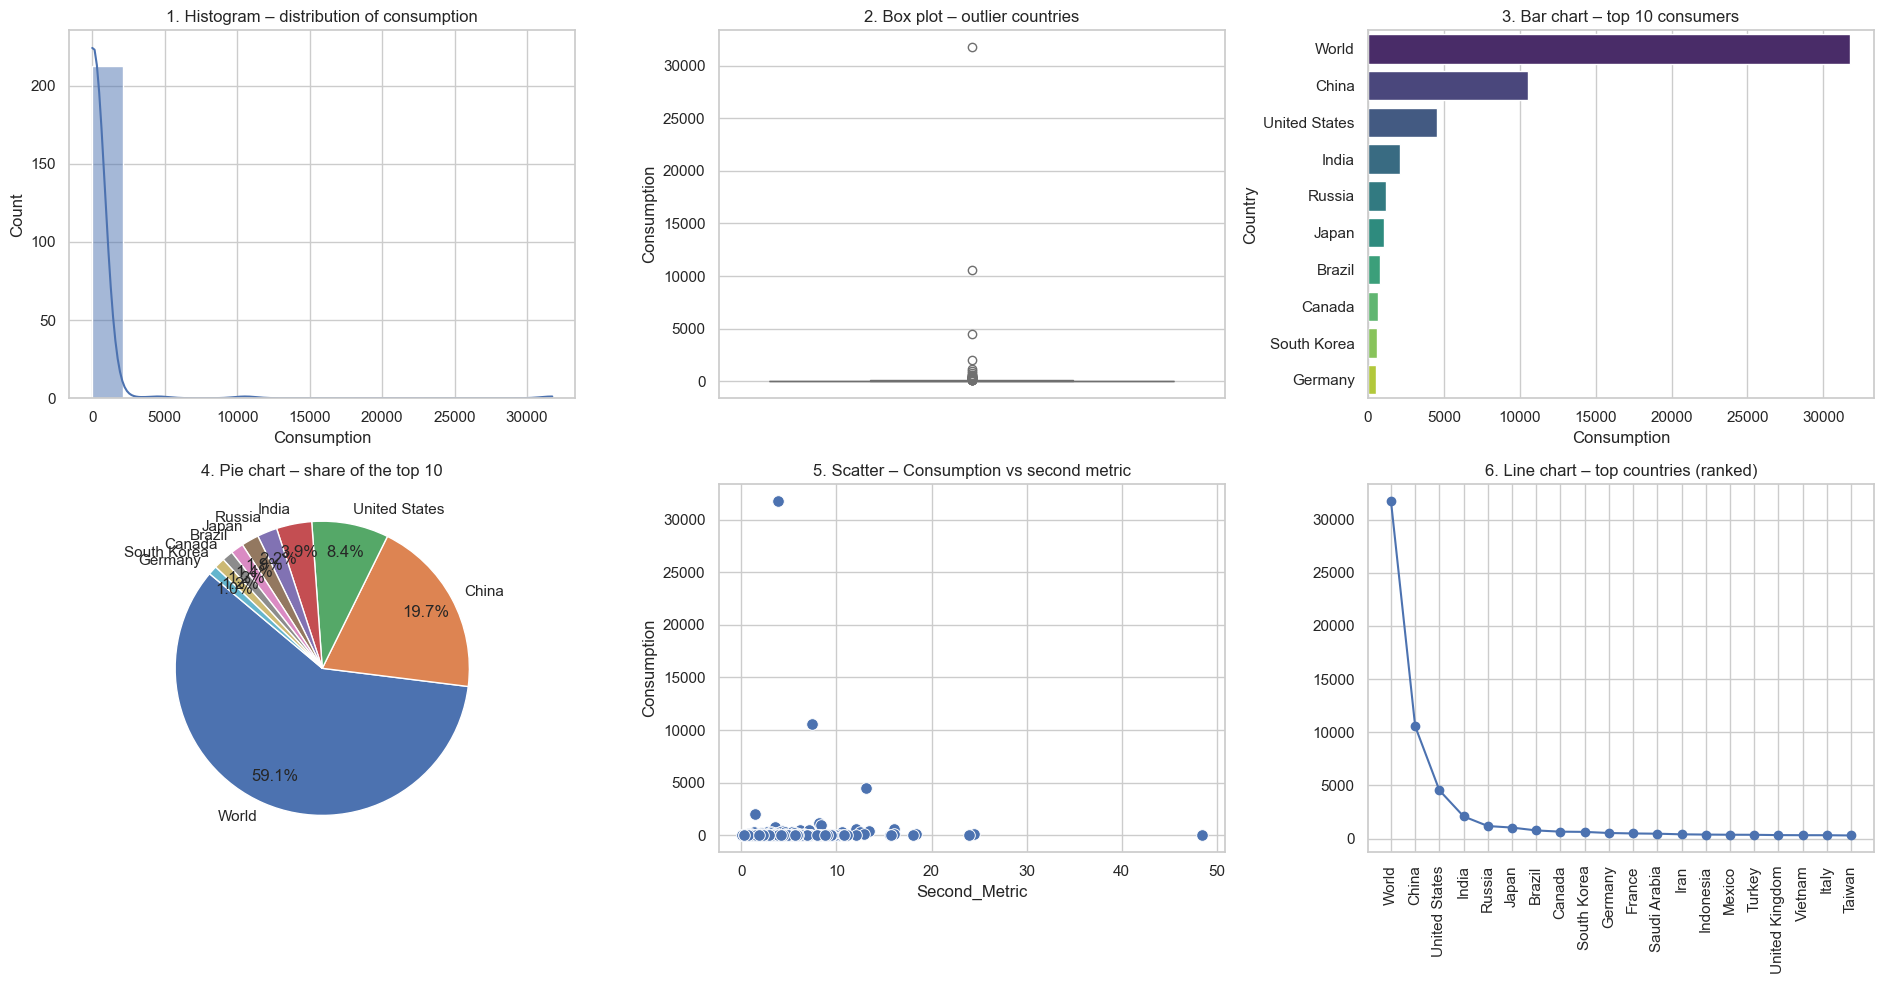

In [6]:
top10 = df_countries.nlargest(10, "Consumption")
top20 = df_countries.nlargest(20, "Consumption")

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

sns.histplot(df_countries["Consumption"], bins=15, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("1. Histogram – distribution of consumption")

sns.boxplot(y=df_countries["Consumption"], ax=axes[0, 1], color="skyblue")
axes[0, 1].set_title("2. Box plot – outlier countries")

sns.barplot(data=top10, x="Consumption", y="Country", hue="Country", palette="viridis", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("3. Bar chart – top 10 consumers")

axes[1, 0].pie(top10["Consumption"], labels=top10["Country"], autopct="%1.1f%%", startangle=140, pctdistance=0.8)
axes[1, 0].set_title("4. Pie chart – share of the top 10")

if "Second_Metric" in df_countries.columns:
    sns.scatterplot(data=df_countries, x="Second_Metric", y="Consumption", ax=axes[1, 1], s=70)
    axes[1, 1].set_title("5. Scatter – Consumption vs second metric")
else:
    axes[1, 1].text(0.5, 0.5, "Only one numeric column\navailable – no scatter plot", ha="center", va="center")
    axes[1, 1].set_title("5. Scatter plot")

axes[1, 2].plot(top20["Country"], top20["Consumption"], marker="o")
axes[1, 2].set_title("6. Line chart – top countries (ranked)")
axes[1, 2].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

## 3. Building and Cleaning the Electricity Dataset  

Hourly smart-meter data for **one full year (2023)** for three consumer groups is generated with realistic behaviour:

* **Residential** – double peak (morning ~8 h and evening ~20 h), higher on weekends
* **Commercial** – daytime peak (~14 h), much lower on weekends and holidays
* **Industrial** – high, almost flat load, small weekend dip
* Demand rises with temperature above ~24 °C (air-conditioning), plus a few random spikes (faults).

> **Using your own real data?** Replace the next cell so that `hourly` has the columns
> `Timestamp, Consumer_Type, Consumption_kWh, Temperature_C, Is_Holiday` – everything after it will work unchanged.
> Example: `hourly = pd.read_csv("my_data.csv", parse_dates=["Timestamp"])`

In [7]:
SEASON_ORDER = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def season_of(m):
    if m in (12, 1, 2):   return "Winter"
    if m in (3, 4, 5, 6):    return "Summer"
    if m in (7, 8, 9): return "Monsoon"
    return "Post-monsoon"

HOLIDAYS = pd.to_datetime(["2023-01-26", "2023-03-08", "2023-04-14", "2023-08-15",
                           "2023-10-02", "2023-10-24", "2023-11-12", "2023-12-25"])

def build_hourly_data(year=2023, seed=42):
    rng = np.random.default_rng(seed)
    ts = pd.date_range(f"{year}-01-01", f"{year}-12-31 23:00", freq="h")
    n_days = len(ts) // 24
    doy, hour = ts.dayofyear.values, ts.hour.values

    # temperature: yearly cycle (peak in May) + daily cycle (peak ~15h) + weather noise
    daily_noise = rng.normal(0, 2.0, n_days)
    temp = (27 + 9 * np.sin(2 * np.pi * (doy - 45) / 365)
            + 4 * np.sin(2 * np.pi * (hour - 9) / 24)
            + daily_noise[doy - 1] + rng.normal(0, 0.8, len(ts)))

    off_day = (ts.dayofweek.values >= 5) | ts.normalize().isin(HOLIDAYS)
    holiday = ts.normalize().isin(HOLIDAYS)

    def shape(h, kind):
        if kind == "Residential":
            return 0.55 + 0.35 * np.exp(-0.5 * ((h - 8) / 1.8) ** 2) + 0.60 * np.exp(-0.5 * ((h - 20) / 2.2) ** 2)
        if kind == "Commercial":
            return 0.35 + 0.90 * np.exp(-0.5 * ((h - 14) / 3.5) ** 2)
        return 0.90 + 0.10 * np.exp(-0.5 * ((h - 13) / 4.0) ** 2)

    kinds = {"Residential": dict(base=120, off=1.12, cool=0.035),
             "Commercial":  dict(base=200, off=0.65, cool=0.025),
             "Industrial":  dict(base=500, off=0.90, cool=0.008)}

    frames = []
    for kind, p in kinds.items():
        load = p["base"] * shape(hour, kind)
        load = load * np.where(off_day, p["off"], 1.0)
        load = load * (1 + p["cool"] * np.clip(temp - 24, 0, None))
        load = load * rng.lognormal(0, 0.06, len(ts))
        frames.append(pd.DataFrame({"Timestamp": ts, "Consumer_Type": kind,
                                    "Consumption_kWh": load,
                                    "Temperature_C": temp.round(2),
                                    "Is_Holiday": holiday.astype(int)}))
    out = pd.concat(frames, ignore_index=True)
    spikes = rng.choice(len(out), size=30, replace=False)       # simulated faults / spikes
    out.loc[spikes, "Consumption_kWh"] *= 1.8
    out["Consumption_kWh"] = out["Consumption_kWh"].round(2)
    return out

hourly = build_hourly_data()
print("Hourly data shape:", hourly.shape)
hourly.head()

Hourly data shape: (26280, 5)


,Timestamp,Consumer_Type,Consumption_kWh,Temperature_C,Is_Holiday
0,2023-01-01 00:00:00,Residential,75.76,19.78,0
1,2023-01-01 01:00:00,Residential,71.51,17.37,0
2,2023-01-01 02:00:00,Residential,73.96,16.90,0
3,2023-01-01 03:00:00,Residential,77.64,17.59,0
4,2023-01-01 04:00:00,Residential,82.49,18.24,0


### 3.1 Data-quality checks
Impossible values (consumption ≤ 0 kWh, temperature outside −10…55 °C) are turned into missing values and filled with a sensible statistic.

In [8]:
print("Missing values per column:\n", hourly.isnull().sum(), "\n")
print("Duplicate rows:", hourly.duplicated().sum())

invalid_cons = (hourly["Consumption_kWh"] <= 0).sum()
invalid_temp = ((hourly["Temperature_C"] < -10) | (hourly["Temperature_C"] > 55)).sum()
print("Invalid consumption values (<= 0):", invalid_cons)
print("Invalid temperature values       :", invalid_temp)

hourly.loc[hourly["Consumption_kWh"] <= 0, "Consumption_kWh"] = np.nan
hourly.loc[(hourly["Temperature_C"] < -10) | (hourly["Temperature_C"] > 55), "Temperature_C"] = np.nan
hourly["Consumption_kWh"] = hourly.groupby("Consumer_Type")["Consumption_kWh"].transform(lambda s: s.fillna(s.median()))
hourly["Temperature_C"] = hourly["Temperature_C"].ffill().bfill()
hourly = hourly.drop_duplicates().reset_index(drop=True)
print("\nAfter cleaning – missing values:", int(hourly.isnull().sum().sum()), "| shape:", hourly.shape)

Missing values per column:
 Timestamp          0
Consumer_Type      0
Consumption_kWh    0
Temperature_C      0
Is_Holiday         0
dtype: int64 

Duplicate rows: 0
Invalid consumption values (<= 0): 0
Invalid temperature values       : 0

After cleaning – missing values: 0 | shape: (26280, 5)


### 3.2 Feature engineering and the three working tables
* `hourly` – hourly readings  
* `daily` – **total** daily demand of all consumers (one row per day)  
* `df` – daily demand **per consumer type** (3 rows per day) – used for sampling, ANOVA, etc.

In [9]:
hourly["Date"] = hourly["Timestamp"].dt.normalize()
hourly["Hour"] = hourly["Timestamp"].dt.hour
hourly["Month"] = hourly["Timestamp"].dt.month
hourly["DayOfWeek"] = hourly["Timestamp"].dt.day_name()
hourly["Is_Weekend"] = (hourly["Timestamp"].dt.dayofweek >= 5).astype(int)
hourly["Season"] = hourly["Month"].map(season_of)

# ---- daily total demand ----
daily = (hourly.groupby("Date")
         .agg(Total_kWh=("Consumption_kWh", "sum"),
              Avg_Temp_C=("Temperature_C", "mean"),
              Max_Temp_C=("Temperature_C", "max"))
         .round(2).reset_index())
daily["Is_Weekend"] = (daily["Date"].dt.dayofweek >= 5).astype(int)
daily["Is_Holiday"] = daily["Date"].isin(HOLIDAYS).astype(int)
daily["Month"] = daily["Date"].dt.month
daily["Season"] = daily["Month"].map(season_of)

# power-cut events per day (count data -> Poisson); more frequent in monsoon / summer
OUTAGE_RATE = {"Winter": 0.25, "Summer": 0.60, "Monsoon": 0.90, "Post-monsoon": 0.30}
rng_out = np.random.default_rng(7)
daily["Outages"] = rng_out.poisson(daily["Season"].map(OUTAGE_RATE).values)

# ---- daily demand per consumer type ----
df = (hourly.groupby(["Date", "Consumer_Type"])
      .agg(Daily_kWh=("Consumption_kWh", "sum"),
           Peak_kWh=("Consumption_kWh", "max"),
           Avg_Temp_C=("Temperature_C", "mean"))
      .round(2).reset_index()
      .merge(daily[["Date", "Is_Weekend", "Is_Holiday", "Month", "Season", "Outages"]], on="Date"))

print("daily shape:", daily.shape, "| df (per consumer type) shape:", df.shape)
hourly.to_csv("electricity_hourly.csv", index=False)
daily.to_csv("electricity_daily.csv", index=False)
print("Saved electricity_hourly.csv and electricity_daily.csv")
display(daily.head())
daily.info()

daily shape: (365, 9) | df (per consumer type) shape: (1095, 10)
Saved electricity_hourly.csv and electricity_daily.csv


,Date,Total_kWh,Avg_Temp_C,Max_Temp_C,Is_Weekend,Is_Holiday,Month,Season,Outages
0,2023-01-01,14837.44,21.53,26.34,1,0,1,Winter,0
1,2023-01-02,16690.32,18.57,23.27,0,0,1,Winter,1
2,2023-01-03,17082.37,22.52,27.79,0,0,1,Winter,0
3,2023-01-04,17179.34,23.25,28.60,0,0,1,Winter,0
4,2023-01-05,16485.18,17.40,22.29,0,0,1,Winter,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        365 non-null    datetime64[ns]
 1   Total_kWh   365 non-null    float64       
 2   Avg_Temp_C  365 non-null    float64       
 3   Max_Temp_C  365 non-null    float64       
 4   Is_Weekend  365 non-null    int64         
 5   Is_Holiday  365 non-null    int64         
 6   Month       365 non-null    int32         
 7   Season      365 non-null    object        
 8   Outages     365 non-null    int64         
dtypes: datetime64[ns](1), float64(3), int32(1), int64(3), object(1)
memory usage: 24.4+ KB


## 4. Electricity Consumption Pattern Analysis

### 4.1 Daily load profile – *when* is electricity used?

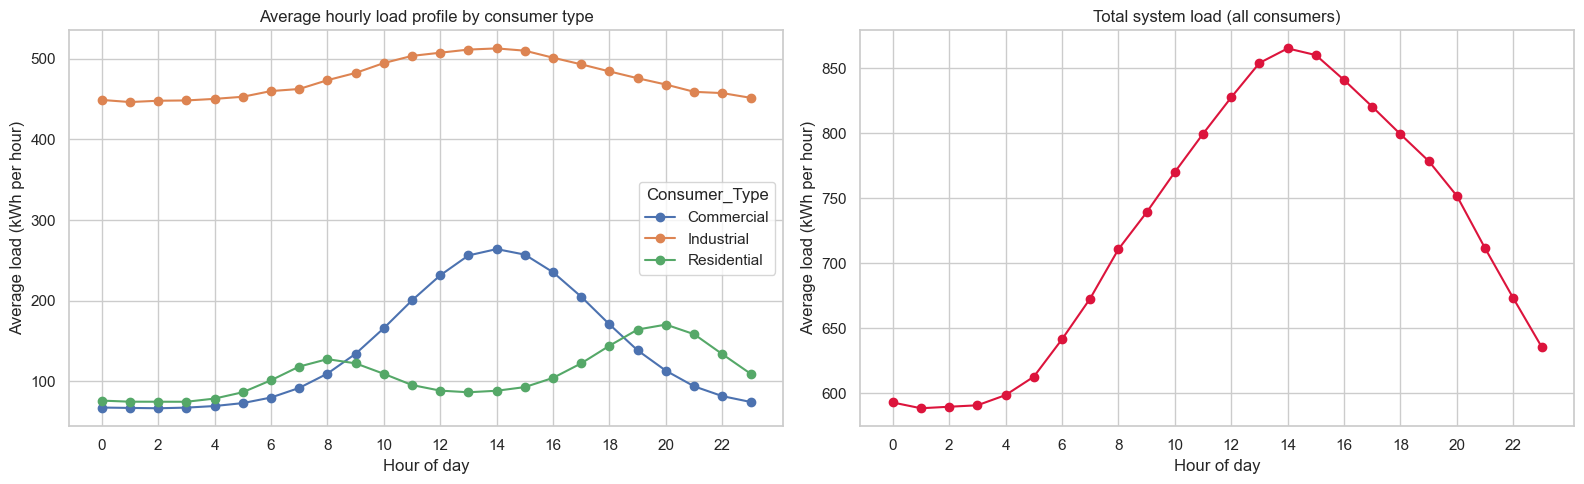

Peak-hour table (load factor = average / peak; closer to 1 means a flatter load):


,Peak_Hour,Peak_Load_kWh,Avg_Load_kWh,Load_Factor
Consumer_Type,,,,
Commercial,14,264.0,138.2,0.52
Industrial,14,512.7,475.0,0.93
Residential,20,170.5,108.6,0.64


System-wide peak hour: 14:00


In [10]:
profile = hourly.groupby(["Hour", "Consumer_Type"])["Consumption_kWh"].mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
profile.plot(ax=axes[0], marker="o")
axes[0].set_title("Average hourly load profile by consumer type")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Average load (kWh per hour)")
axes[0].set_xticks(range(0, 24, 2))

profile.sum(axis=1).plot(ax=axes[1], marker="o", color="crimson")
axes[1].set_title("Total system load (all consumers)")
axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Average load (kWh per hour)")
axes[1].set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

peak_table = pd.DataFrame({"Peak_Hour": profile.idxmax(),
                           "Peak_Load_kWh": profile.max().round(1),
                           "Avg_Load_kWh": profile.mean().round(1)})
peak_table["Load_Factor"] = (peak_table["Avg_Load_kWh"] / peak_table["Peak_Load_kWh"]).round(2)
system_peak_hour = profile.sum(axis=1).idxmax()
print("Peak-hour table (load factor = average / peak; closer to 1 means a flatter load):")
display(peak_table)
print(f"System-wide peak hour: {system_peak_hour}:00")

### 4.2 Weekly pattern – day of week × hour heat-map

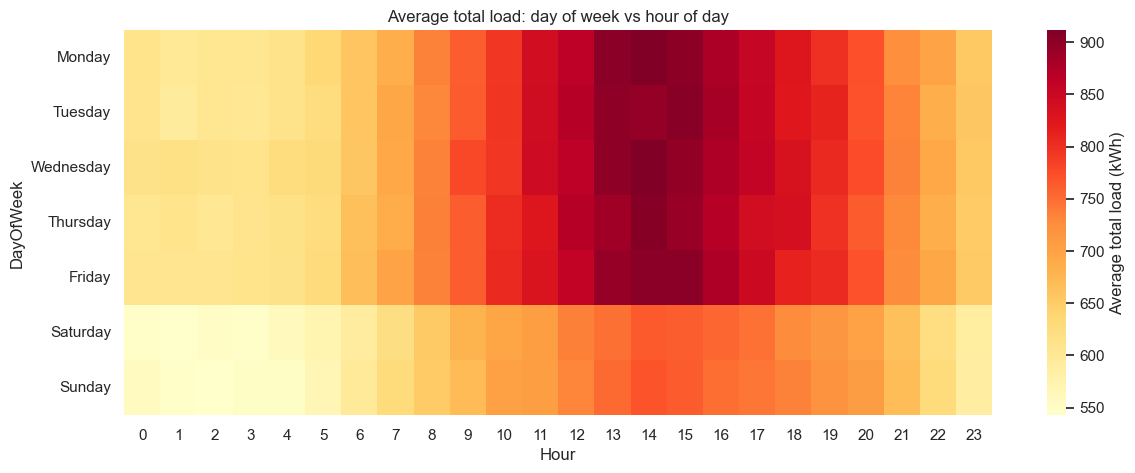

Average daily demand by weekday (kWh):
Date
Monday       17934.0
Tuesday      17929.0
Wednesday    18015.0
Thursday     17883.0
Friday       17912.0
Saturday     15806.0
Sunday       15821.0


In [11]:
total_hourly = hourly.groupby("Timestamp")["Consumption_kWh"].sum().reset_index()
total_hourly["Hour"] = total_hourly["Timestamp"].dt.hour
total_hourly["DayOfWeek"] = total_hourly["Timestamp"].dt.day_name()
heat = total_hourly.pivot_table(index="DayOfWeek", columns="Hour", values="Consumption_kWh", aggfunc="mean").reindex(DAY_ORDER)

plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Average total load (kWh)"})
plt.title("Average total load: day of week vs hour of day")
plt.show()

weekday_avg = daily.groupby(daily["Date"].dt.day_name())["Total_kWh"].mean().reindex(DAY_ORDER).round(0)
print("Average daily demand by weekday (kWh):")
print(weekday_avg.to_string())

### 4.3 Monthly and seasonal pattern

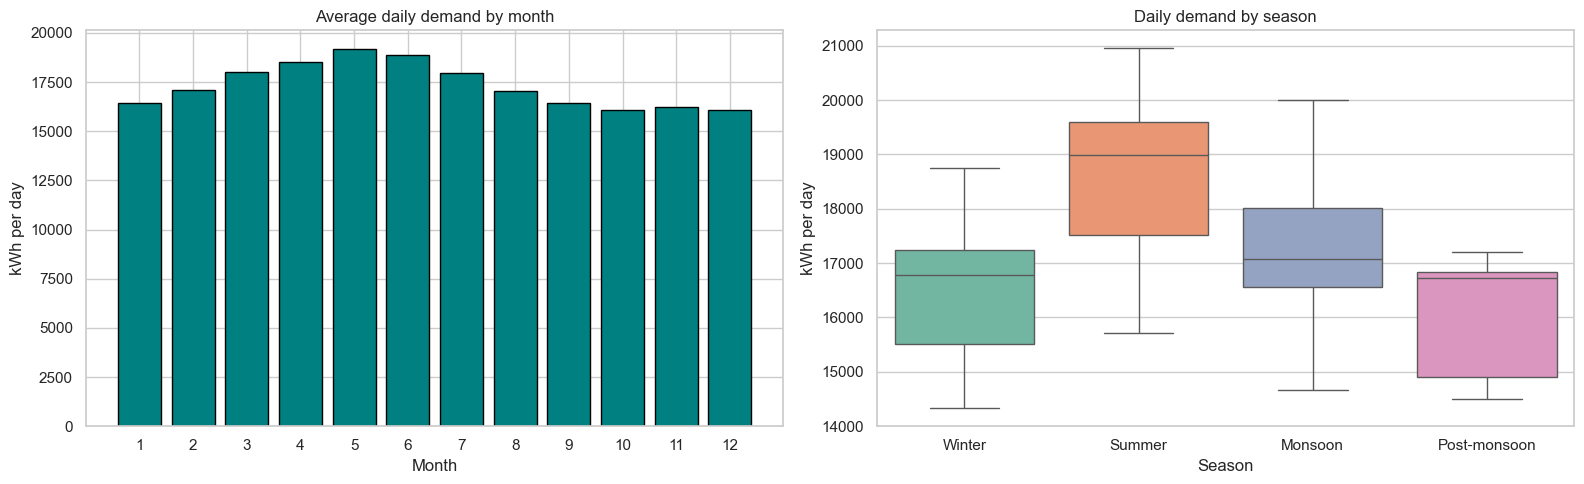

Highest-demand month: 5 | lowest-demand month: 12
Season
Winter          16502.0
Summer          18644.0
Monsoon         17155.0
Post-monsoon    16155.0


In [12]:
monthly = daily.groupby("Month")["Total_kWh"].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(monthly.index, monthly.values, color="teal", edgecolor="black")
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Average daily demand by month")
axes[0].set_xlabel("Month"); axes[0].set_ylabel("kWh per day")

sns.boxplot(data=daily, x="Season", y="Total_kWh", order=SEASON_ORDER, hue="Season", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Daily demand by season")
axes[1].set_ylabel("kWh per day")
plt.tight_layout(); plt.show()

print("Highest-demand month:", monthly.idxmax(), "| lowest-demand month:", monthly.idxmin())
print(daily.groupby("Season")["Total_kWh"].mean().reindex(SEASON_ORDER).round(0).to_string())

### 4.4 Outlier / anomaly detection (IQR rule on daily demand, z-score on hourly readings)

In [13]:
q1, q3 = daily["Total_kWh"].quantile([0.25, 0.75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_days = daily[(daily["Total_kWh"] < low_fence) | (daily["Total_kWh"] > high_fence)]
print(f"IQR fences: {low_fence:,.0f} to {high_fence:,.0f} kWh  ->  {len(out_days)} unusual day(s)")
if len(out_days):
    display(out_days[["Date", "Total_kWh", "Avg_Temp_C"]].head(10))

# hourly spikes: compare each reading with the usual value for the same consumer type and hour of day
grp = hourly.groupby(["Consumer_Type", "Hour"])["Consumption_kWh"]
hourly["z_score"] = (hourly["Consumption_kWh"] - grp.transform("mean")) / grp.transform("std")
spikes = hourly[hourly["z_score"].abs() > 3.5]
print(f"\nHourly readings with |z| > 3.5: {len(spikes)}  (mostly the simulated meter faults / spikes)")
display(spikes[["Timestamp", "Consumer_Type", "Consumption_kWh", "z_score"]].sort_values("z_score", ascending=False).head(8))

IQR fences: 13,672 to 21,548 kWh  ->  0 unusual day(s)

Hourly readings with |z| > 3.5: 32  (mostly the simulated meter faults / spikes)


,Timestamp,Consumer_Type,Consumption_kWh,z_score
23866,2023-09-22 10:00:00,Industrial,978.95,9.732555
18474,2023-02-09 18:00:00,Industrial,938.68,9.682904
23102,2023-08-21 14:00:00,Industrial,992.16,9.370032
25798,2023-12-11 22:00:00,Industrial,850.78,8.189092
2665,2023-04-22 01:00:00,Residential,165.20,7.931914
21022,2023-05-26 22:00:00,Industrial,829.13,7.738506
17827,2023-01-13 19:00:00,Industrial,853.11,7.619308
21552,2023-06-18 00:00:00,Industrial,730.72,7.346680


## 5. Descriptive Statistics and Visualisations of Daily Demand  

In [14]:
describe_all(daily["Total_kWh"], "Total daily demand (kWh)")
print()
print("Daily demand per consumer type (kWh):")
display(df.groupby("Consumer_Type")["Daily_kWh"].describe().round(1))

--- Descriptive statistics: Total daily demand (kWh) ---
Mean              : 17,324.55
Median            : 17,081.11
Mode              : 14,326.93
Variance          : 2,361,315.07
Standard deviation: 1,536.66
Minimum / Maximum : 14,326.93 / 20,950.85
Q1 / Q2 / Q3      : 16,625.46 / 17,081.11 / 18,594.51
IQR               : 1,969.05
Skewness          : 0.057   Kurtosis: -0.674

summary (describe):
count      365.00
mean     17324.55
std       1536.66
min      14326.93
25%      16625.46
50%      17081.11
75%      18594.51
max      20950.85

Daily demand per consumer type (kWh):


,count,mean,std,min,25%,50%,75%,max
Consumer_Type,,,,,,,,
Commercial,365.0,3317.2,710.5,2065.1,2737.4,3329.3,3933.1,4713.0
Industrial,365.0,11400.2,705.0,9829.2,11022.8,11425.6,11929.6,12945.0
Residential,365.0,2607.1,391.8,2098.0,2226.7,2511.9,2898.4,3947.9


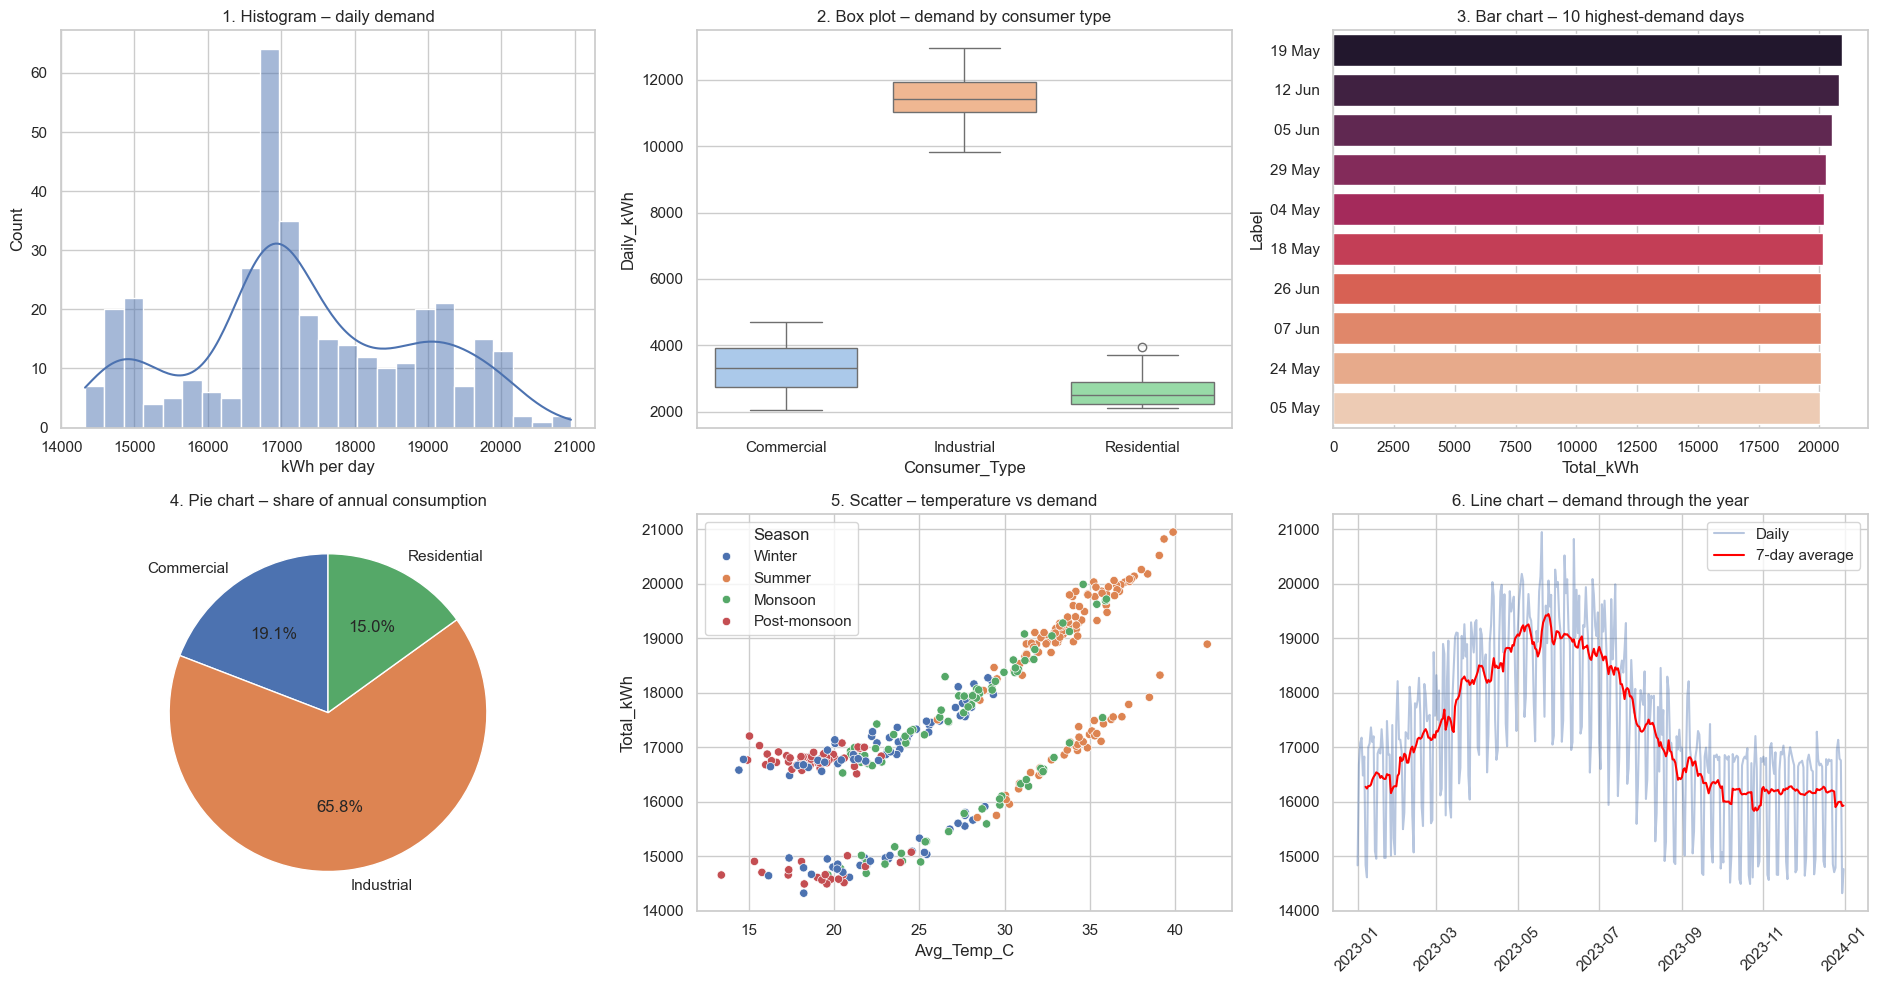

In [15]:
top10_days = daily.nlargest(10, "Total_kWh").copy()
top10_days["Label"] = top10_days["Date"].dt.strftime("%d %b")
share = df.groupby("Consumer_Type")["Daily_kWh"].sum()

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

sns.histplot(daily["Total_kWh"], bins=25, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("1. Histogram – daily demand")
axes[0, 0].set_xlabel("kWh per day")

sns.boxplot(data=df, x="Consumer_Type", y="Daily_kWh", hue="Consumer_Type", palette="pastel", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("2. Box plot – demand by consumer type")

sns.barplot(data=top10_days, x="Total_kWh", y="Label", hue="Label", palette="rocket", legend=False, ax=axes[0, 2])
axes[0, 2].set_title("3. Bar chart – 10 highest-demand days")

axes[1, 0].pie(share.values, labels=share.index, autopct="%1.1f%%", startangle=90)
axes[1, 0].set_title("4. Pie chart – share of annual consumption")

sns.scatterplot(data=daily, x="Avg_Temp_C", y="Total_kWh", hue="Season", hue_order=SEASON_ORDER, ax=axes[1, 1])
axes[1, 1].set_title("5. Scatter – temperature vs demand")

axes[1, 2].plot(daily["Date"], daily["Total_kWh"], alpha=0.4, label="Daily")
axes[1, 2].plot(daily["Date"], daily["Total_kWh"].rolling(7).mean(), color="red", label="7-day average")
axes[1, 2].set_title("6. Line chart – demand through the year")
axes[1, 2].legend(); axes[1, 2].tick_params(axis="x", rotation=45)

plt.tight_layout(); plt.show()

## 6. Probability Distributions  

### 6.1 The four standard distributions 

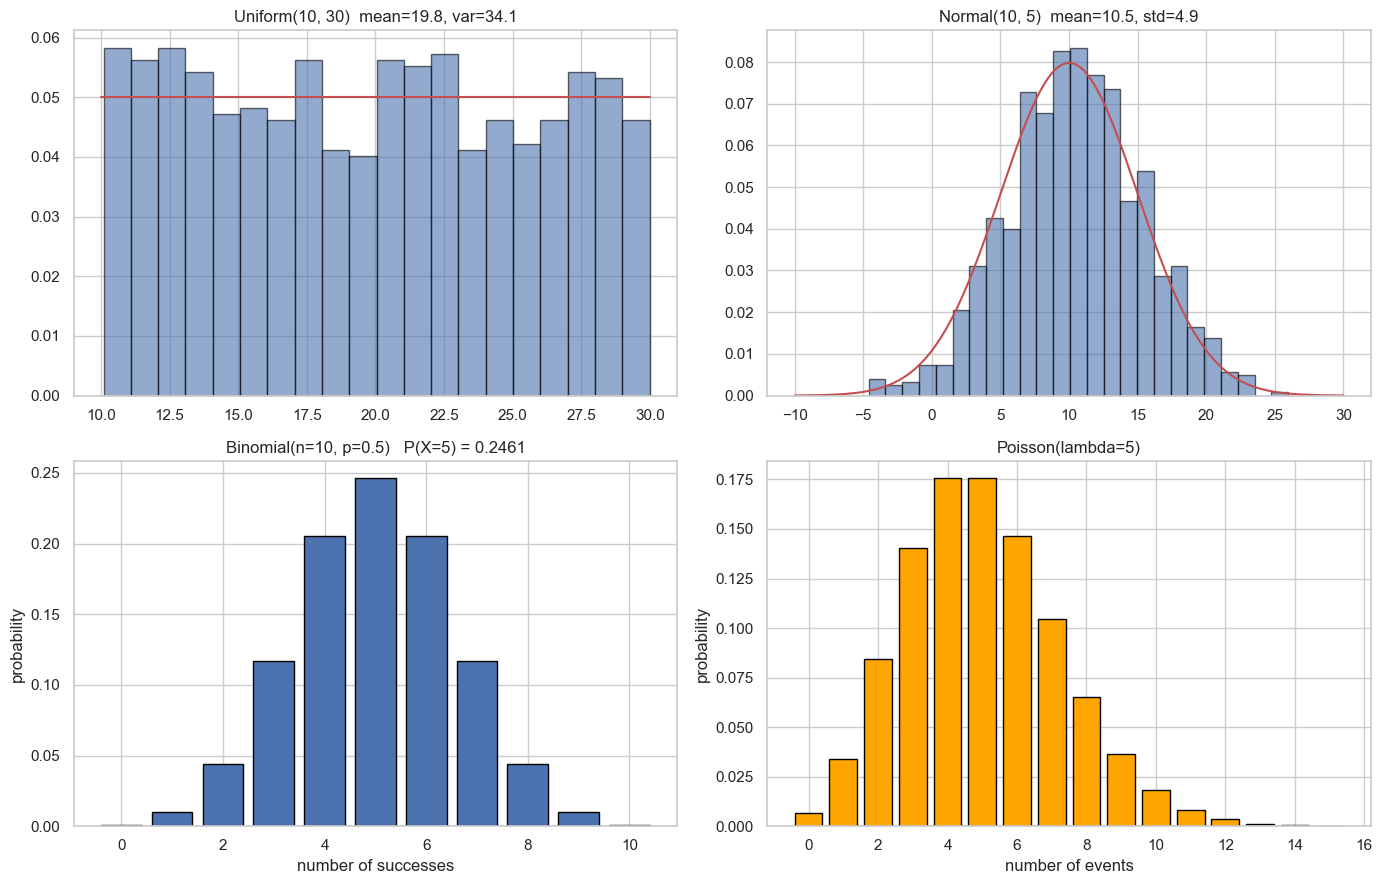

In [16]:
from scipy.stats import uniform, norm, binom, poisson

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Uniform
u = uniform.rvs(loc=10, scale=20, size=1000)
axes[0, 0].hist(u, bins=20, density=True, alpha=0.6, edgecolor="black")
x = np.linspace(10, 30, 100)
axes[0, 0].plot(x, uniform.pdf(x, loc=10, scale=20), "r-")
axes[0, 0].set_title(f"Uniform(10, 30)  mean={u.mean():.1f}, var={u.var():.1f}")

# Normal
nrm = norm.rvs(loc=10, scale=5, size=1000)
axes[0, 1].hist(nrm, bins=25, density=True, alpha=0.6, edgecolor="black")
x = np.linspace(-10, 30, 200)
axes[0, 1].plot(x, norm.pdf(x, 10, 5), "r-")
axes[0, 1].set_title(f"Normal(10, 5)  mean={nrm.mean():.1f}, std={nrm.std():.1f}")

# Binomial
n_b, p_b = 10, 0.5
k = np.arange(0, n_b + 1)
axes[1, 0].bar(k, binom.pmf(k, n_b, p_b), edgecolor="black")
axes[1, 0].set_title(f"Binomial(n=10, p=0.5)   P(X=5) = {binom.pmf(5, n_b, p_b):.4f}")
axes[1, 0].set_xlabel("number of successes"); axes[1, 0].set_ylabel("probability")

# Poisson
k = np.arange(0, 16)
axes[1, 1].bar(k, poisson.pmf(k, 5), edgecolor="black", color="orange")
axes[1, 1].set_title("Poisson(lambda=5)")
axes[1, 1].set_xlabel("number of events"); axes[1, 1].set_ylabel("probability")

plt.tight_layout(); plt.show()

### 6.2 Fitting the distributions to the electricity data

Uniform model mean = 17,580 | actual mean = 17,325
Shapiro-Wilk normality test: W=0.9643, p=9.024e-08 -> NOT perfectly normal (skewed by the hot-season peak)
P(high-demand day) = 0.249  |  P(exactly 2 in a week) = 0.311  |  P(3 or more) = 0.242
Average outages per day (lambda) = 0.56  |  P(2 or more outages in a day) = 0.109
Sum of empirical probabilities = 1.00


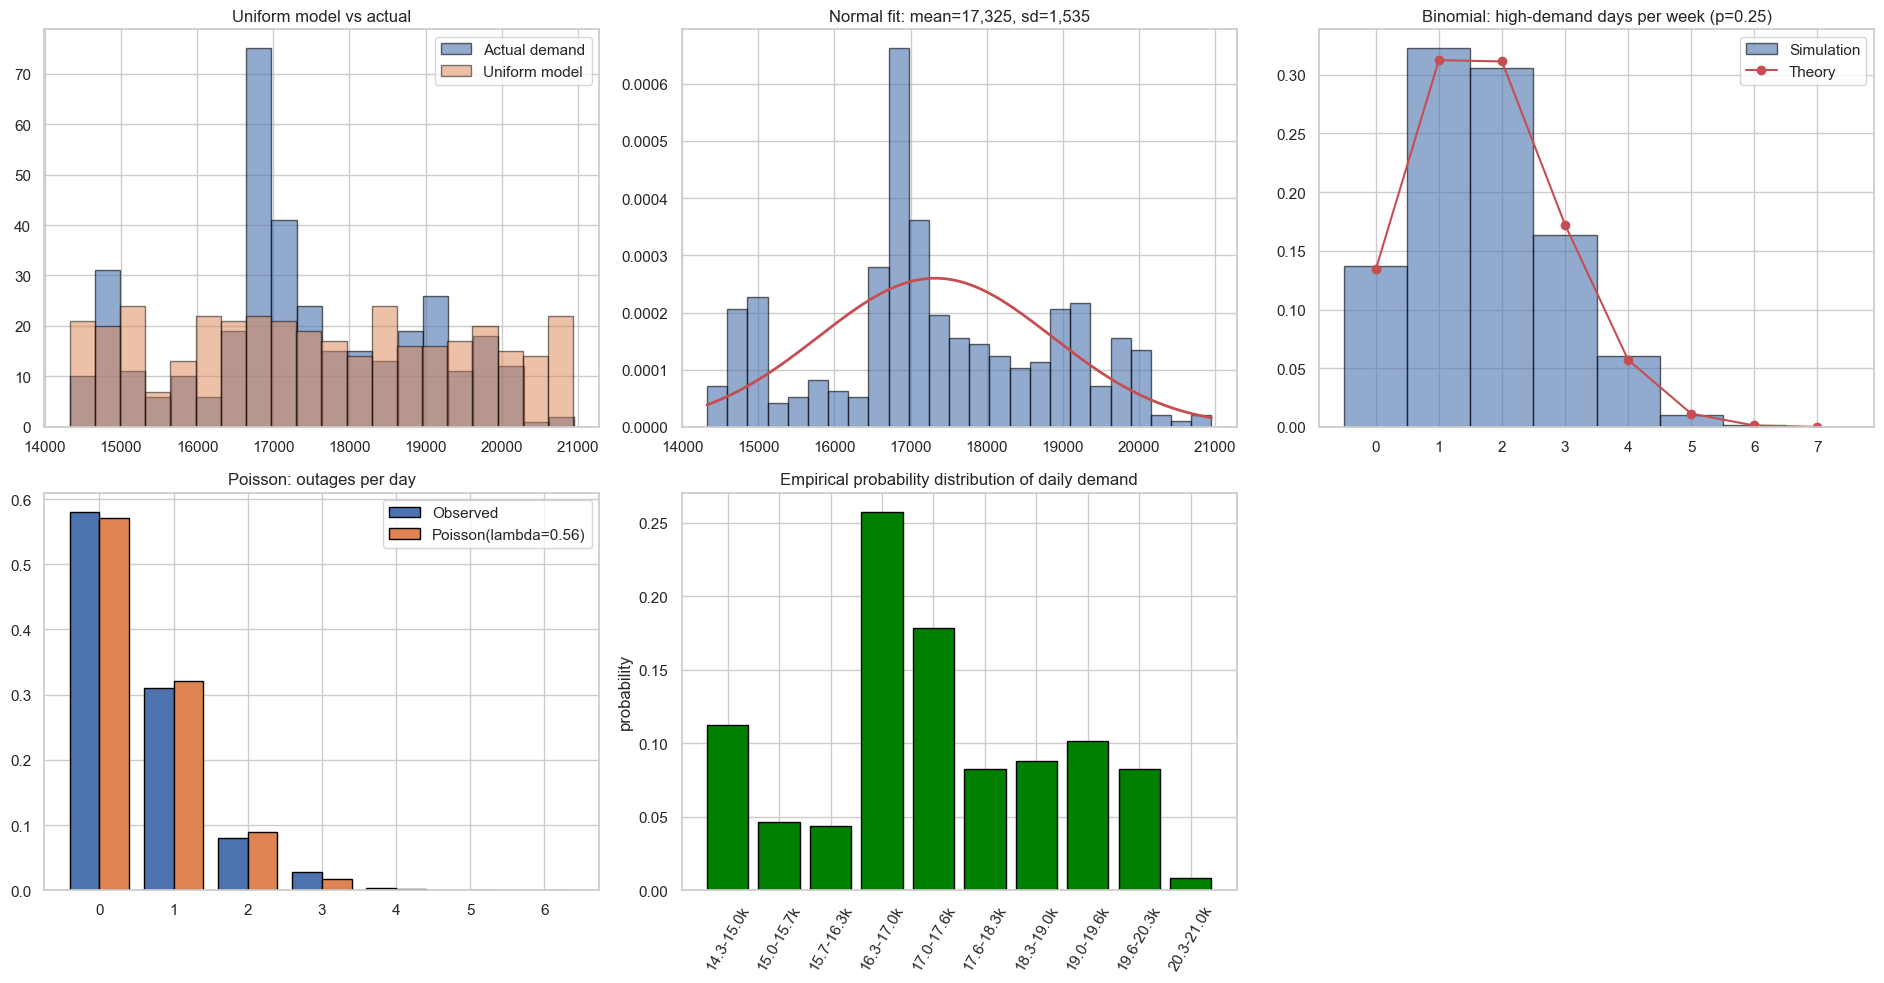

In [17]:
x_dem = daily["Total_kWh"]
fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# --- Uniform: what if demand were equally likely anywhere between min and max? ---
uni_sim = np.random.uniform(x_dem.min(), x_dem.max(), len(x_dem))
axes[0, 0].hist(x_dem, bins=20, alpha=0.6, label="Actual demand", edgecolor="black")
axes[0, 0].hist(uni_sim, bins=20, alpha=0.5, label="Uniform model", edgecolor="black")
axes[0, 0].set_title("Uniform model vs actual"); axes[0, 0].legend()
print(f"Uniform model mean = {uni_sim.mean():,.0f} | actual mean = {x_dem.mean():,.0f}")

# --- Normal: fit mean and sigma ---
mu_fit, sd_fit = norm.fit(x_dem)
axes[0, 1].hist(x_dem, bins=25, density=True, alpha=0.6, edgecolor="black")
xs = np.linspace(x_dem.min(), x_dem.max(), 300)
axes[0, 1].plot(xs, norm.pdf(xs, mu_fit, sd_fit), "r-", lw=2)
axes[0, 1].set_title(f"Normal fit: mean={mu_fit:,.0f}, sd={sd_fit:,.0f}")
sh_stat, sh_p = stats.shapiro(x_dem)
print(f"Shapiro-Wilk normality test: W={sh_stat:.4f}, p={sh_p:.4g} ->",
      "looks normal" if sh_p > 0.05 else "NOT perfectly normal (skewed by the hot-season peak)")

# --- Binomial: number of 'high-demand' days in a week ---
threshold = x_dem.quantile(0.75)
p_high = (x_dem > threshold).mean()
n_week = 7
sim_weeks = np.random.binomial(n_week, p_high, 5000)
k = np.arange(0, n_week + 1)
axes[0, 2].hist(sim_weeks, bins=np.arange(-0.5, n_week + 1.5), density=True, alpha=0.6, edgecolor="black", label="Simulation")
axes[0, 2].plot(k, binom.pmf(k, n_week, p_high), "ro-", label="Theory")
axes[0, 2].set_title(f"Binomial: high-demand days per week (p={p_high:.2f})"); axes[0, 2].legend()
print(f"P(high-demand day) = {p_high:.3f}  |  P(exactly 2 in a week) = {binom.pmf(2, n_week, p_high):.3f}"
      f"  |  P(3 or more) = {1 - binom.cdf(2, n_week, p_high):.3f}")

# --- Poisson: power-cut events per day ---
lam = daily["Outages"].mean()
obs = daily["Outages"].value_counts(normalize=True).sort_index()
k = np.arange(0, int(obs.index.max()) + 3)
axes[1, 0].bar(obs.index - 0.2, obs.values, width=0.4, label="Observed", edgecolor="black")
axes[1, 0].bar(k + 0.2, poisson.pmf(k, lam), width=0.4, label=f"Poisson(lambda={lam:.2f})", edgecolor="black")
axes[1, 0].set_title("Poisson: outages per day"); axes[1, 0].legend()
print(f"Average outages per day (lambda) = {lam:.2f}  |  P(2 or more outages in a day) = {1 - poisson.cdf(1, lam):.3f}")

# --- Empirical probability distribution of demand ---
bins = pd.cut(x_dem, bins=10)
prob = bins.value_counts(normalize=True).sort_index()
prob.index = [f"{i.left/1000:.1f}-{i.right/1000:.1f}k" for i in prob.index]
axes[1, 1].bar(prob.index, prob.values, edgecolor="black", color="green")
axes[1, 1].set_title("Empirical probability distribution of daily demand")
axes[1, 1].tick_params(axis="x", rotation=60); axes[1, 1].set_ylabel("probability")
print(f"Sum of empirical probabilities = {prob.sum():.2f}")

axes[1, 2].axis("off")
plt.tight_layout(); plt.show()

## 7. Sampling Techniques 
Population = all 1,095 daily readings (365 days × 3 consumer types) in `df`. Seven sampling methods are compared with the population.

| Method | Idea |
|---|---|
| Simple random | every row has the same chance |
| With replacement | the same row may be picked more than once |
| Without replacement | a row can be picked only once |
| Fraction | take a % of the data |
| Systematic | every *k*-th row |
| Stratified | equal number from each consumer type |
| Cluster | randomly pick whole groups (months) |

In [18]:
pop = df["Daily_kWh"]

rng_s = np.random.default_rng(6)
chosen_months = rng_s.choice(df["Month"].unique(), size=3, replace=False)

samples = {
    "Simple random":        df.sample(n=100, random_state=1),
    "With replacement":     df.sample(n=100, replace=True, random_state=2),
    "Without replacement":  df.sample(n=100, replace=False, random_state=3),
    "Fraction (10%)":       df.sample(frac=0.10, random_state=4),
    "Systematic (k=10)":    df.iloc[::10],
    "Stratified (30/type)": df.groupby("Consumer_Type").sample(n=30, random_state=5),
    f"Cluster (months {sorted(chosen_months.tolist())})": df[df["Month"].isin(chosen_months)],
}

rows = [{"Method": "Population", "Size": len(df), "Mean": pop.mean(), "Median": pop.median(),
         "Std": pop.std(), "Error in mean (%)": 0.0}]
for name, s in samples.items():
    m = s["Daily_kWh"].mean()
    rows.append({"Method": name, "Size": len(s), "Mean": m, "Median": s["Daily_kWh"].median(),
                 "Std": s["Daily_kWh"].std(), "Error in mean (%)": abs(m - pop.mean()) / pop.mean() * 100})
comparison = pd.DataFrame(rows).set_index("Method").round(2)
comparison

,Size,Mean,Median,Std,Error in mean (%)
Method,,,,,
Population,1095,5774.85,3352.20,4038.01,0.00
Simple random,100,5290.07,3325.92,3881.55,8.39
With replacement,100,6360.79,3375.66,4181.74,10.15
Without replacement,100,6160.10,3539.43,4115.37,6.67
Fraction (10%),110,6088.12,3471.30,4105.09,5.42
Systematic (k=10),110,5805.36,3353.67,4031.05,0.53
Stratified (30/type),90,5653.67,3257.81,4038.61,2.10
"Cluster (months [5, 6, 7])",276,6225.21,4057.02,4070.94,7.80


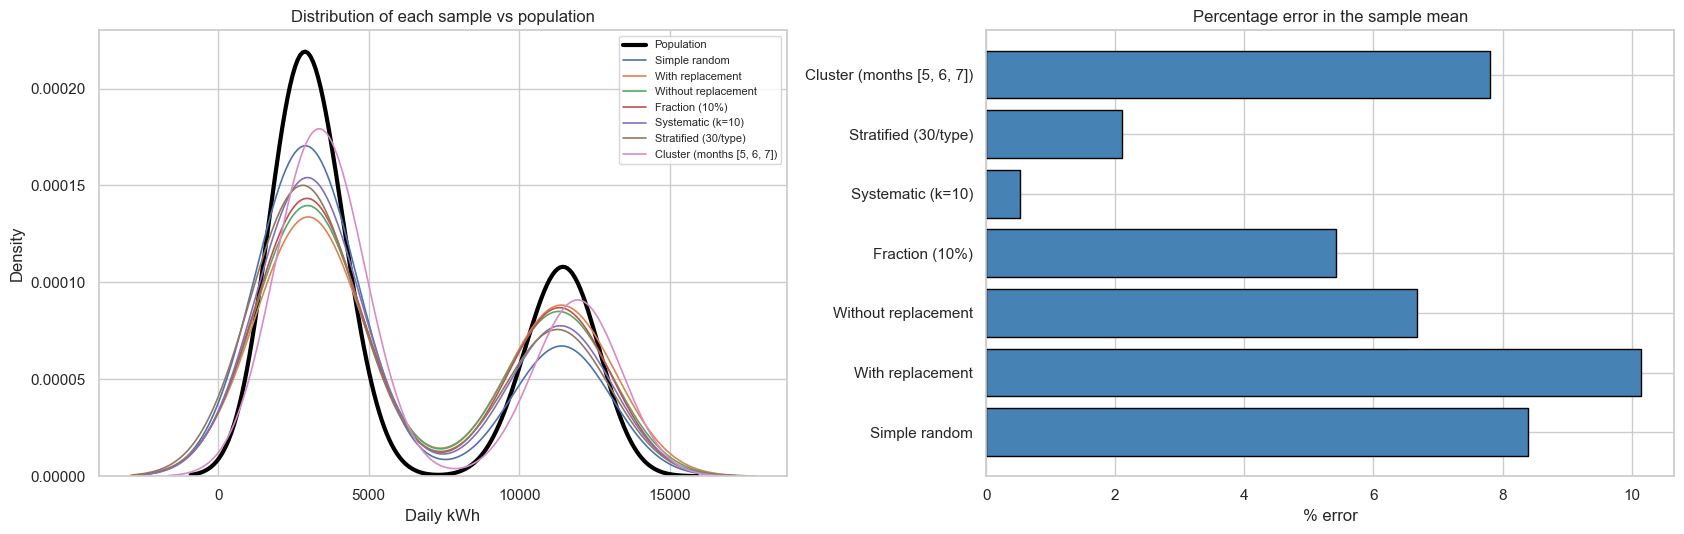

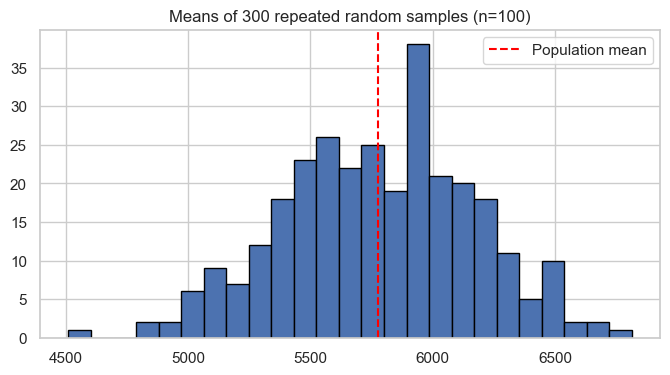

Best method for this run (lowest error): Systematic (k=10)


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

sns.kdeplot(pop, ax=axes[0], color="black", lw=3, label="Population")
for name, s in samples.items():
    sns.kdeplot(s["Daily_kWh"], ax=axes[0], lw=1.2, label=name)
axes[0].set_title("Distribution of each sample vs population"); axes[0].set_xlabel("Daily kWh")
axes[0].legend(fontsize=8)

err = comparison.drop("Population")["Error in mean (%)"]
axes[1].barh(err.index, err.values, color="steelblue", edgecolor="black")
axes[1].set_title("Percentage error in the sample mean"); axes[1].set_xlabel("% error")
plt.tight_layout(); plt.show()

# variability of the sample mean over repeated sampling
means = [df.sample(n=100)["Daily_kWh"].mean() for _ in range(300)]
plt.figure(figsize=(8, 4))
plt.hist(means, bins=25, edgecolor="black")
plt.axvline(pop.mean(), color="red", ls="--", label="Population mean")
plt.title("Means of 300 repeated random samples (n=100)"); plt.legend(); plt.show()
print("Best method for this run (lowest error):", err.idxmin())

## 8. Central Limit Theorem, Point Estimation and Standard Error

### 8.1 Strongly skewed (exponential) population

Population mean: 50.08 | Population std: 48.714


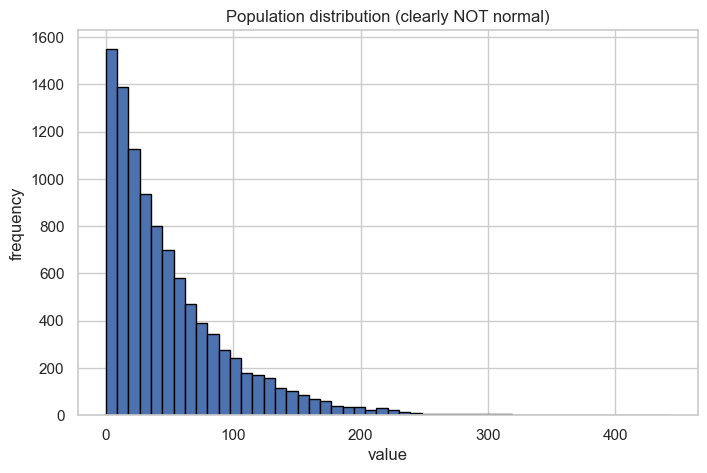


Point estimate of population mean: 50.11
Difference from actual mean      : 0.03
Theoretical standard error       : 8.894
Observed standard error          : 9.162


In [20]:
np.random.seed(50)
population = np.random.exponential(scale=50, size=10000)
pop_mean, pop_std = population.mean(), population.std()
print("Population mean:", round(pop_mean, 3), "| Population std:", round(pop_std, 3))

plt.figure(figsize=(8, 5))
plt.hist(population, bins=50, edgecolor="black")
plt.title("Population distribution (clearly NOT normal)")
plt.xlabel("value"); plt.ylabel("frequency"); plt.show()

# Point estimation: 1000 samples of size 30
sample_size, number_of_samples = 30, 1000
sample_means = np.array([np.random.choice(population, size=sample_size).mean() for _ in range(number_of_samples)])
standard_error = pop_std / np.sqrt(sample_size)
print("\nPoint estimate of population mean:", round(sample_means.mean(), 3))
print("Difference from actual mean      :", round(abs(pop_mean - sample_means.mean()), 3))
print("Theoretical standard error       :", round(standard_error, 3))
print("Observed standard error          :", round(sample_means.std(ddof=1), 3))

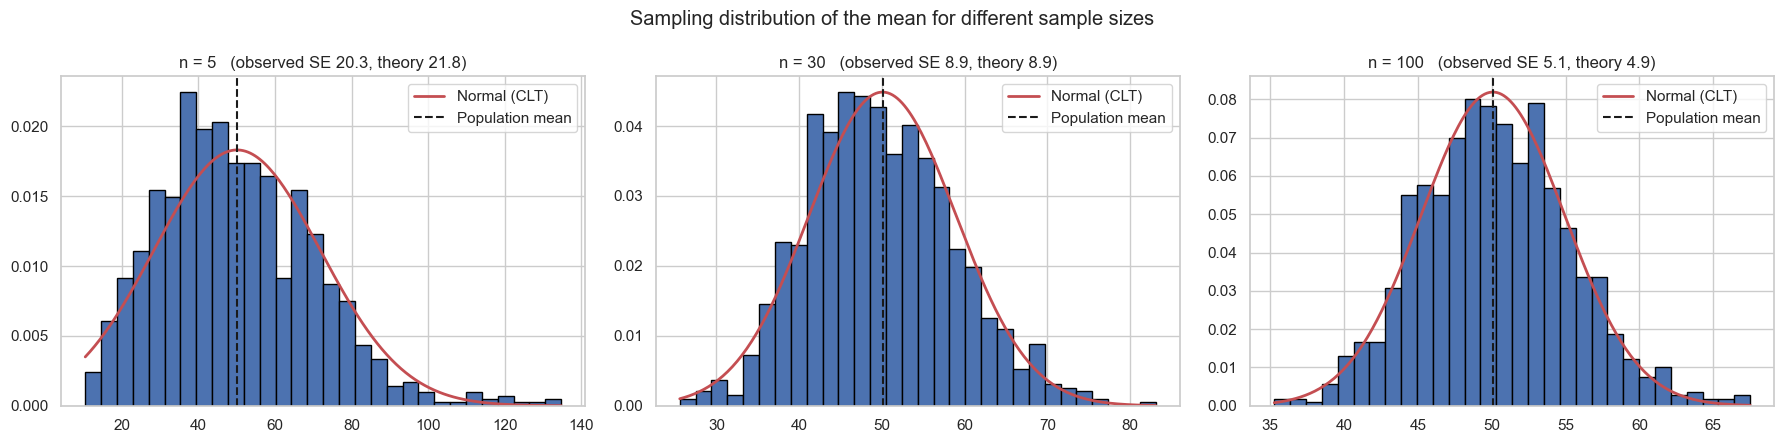

In [21]:
# CLT: the distribution of sample means becomes normal as the sample size grows
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, n in zip(axes, [5, 30, 100]):
    means_n = np.array([np.random.choice(population, size=n).mean() for _ in range(1000)])
    ax.hist(means_n, bins=30, edgecolor="black", density=True)
    xs = np.linspace(means_n.min(), means_n.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, pop_mean, pop_std / np.sqrt(n)), "r-", lw=2, label="Normal (CLT)")
    ax.axvline(pop_mean, color="k", ls="--", label="Population mean")
    ax.set_title(f"n = {n}   (observed SE {means_n.std(ddof=1):.1f}, theory {pop_std/np.sqrt(n):.1f})")
    ax.legend()
plt.suptitle("Sampling distribution of the mean for different sample sizes")
plt.tight_layout(); plt.show()

### 8.2 CLT and point estimation on the real electricity data

Population size: 365 days | mean = 17,324.5 kWh | sd = 1,534.6 kWh

--- CLT results (1000 samples, n = 50) ---
Population mean        : 17,324.55
Mean of sample means   : 17,337.30
Theoretical SE (s/sqrt n): 217.02
Observed SE            : 220.96


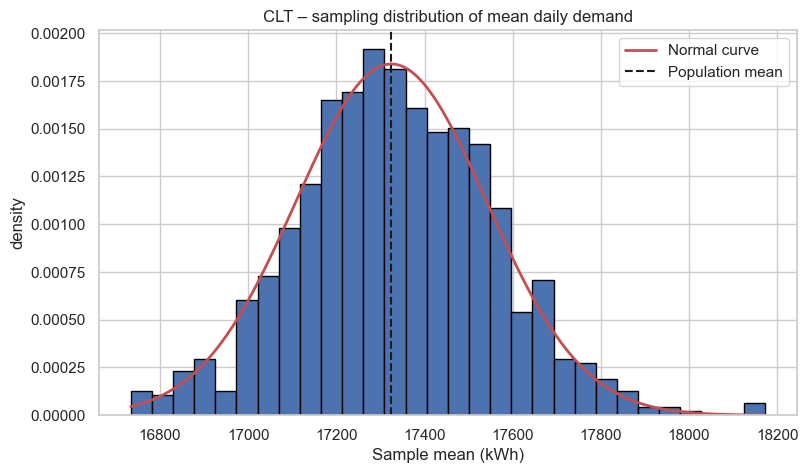


--- Point estimation from a single sample of 50 days ---
Estimated mean     : 17,228.59
Estimated variance : 2,276,698.28
Estimated std dev  : 1,508.87
Absolute error in the mean: 95.95 kWh


In [22]:
pop_data = daily["Total_kWh"]
mu_pop, sigma_pop = pop_data.mean(), pop_data.std(ddof=0)
print(f"Population size: {len(pop_data)} days | mean = {mu_pop:,.1f} kWh | sd = {sigma_pop:,.1f} kWh")

n = 50
means_real = np.array([pop_data.sample(n=n, replace=True, random_state=i).mean() for i in range(1000)])
theoretical_se = sigma_pop / np.sqrt(n)
observed_se = means_real.std(ddof=1)
print("\n--- CLT results (1000 samples, n = 50) ---")
print(f"Population mean        : {mu_pop:,.2f}")
print(f"Mean of sample means   : {means_real.mean():,.2f}")
print(f"Theoretical SE (s/sqrt n): {theoretical_se:,.2f}")
print(f"Observed SE            : {observed_se:,.2f}")

plt.figure(figsize=(9, 5))
plt.hist(means_real, bins=30, edgecolor="black", density=True)
xs = np.linspace(means_real.min(), means_real.max(), 200)
plt.plot(xs, stats.norm.pdf(xs, mu_pop, theoretical_se), "r-", lw=2, label="Normal curve")
plt.axvline(mu_pop, color="k", ls="--", label="Population mean")
plt.xlabel("Sample mean (kWh)"); plt.ylabel("density")
plt.title("CLT – sampling distribution of mean daily demand"); plt.legend(); plt.show()

# Point estimation from ONE sample of 50 days
one_sample = pop_data.sample(n=50, random_state=42)
print("\n--- Point estimation from a single sample of 50 days ---")
print(f"Estimated mean     : {one_sample.mean():,.2f}")
print(f"Estimated variance : {one_sample.var():,.2f}")
print(f"Estimated std dev  : {one_sample.std():,.2f}")
print(f"Absolute error in the mean: {abs(one_sample.mean() - mu_pop):,.2f} kWh")

## 9. Confidence Intervals and One-Sample Hypothesis Tests

### 9.1 Confidence intervals for mean daily demand

Sample size = 365, mean = 17,324.55, std = 1,536.66, SE = 80.43
90% CI: (17,191.9, 17,457.2)   margin = 132.6
95% CI: (17,166.4, 17,482.7)   margin = 158.2
99% CI: (17,116.3, 17,532.8)   margin = 208.3


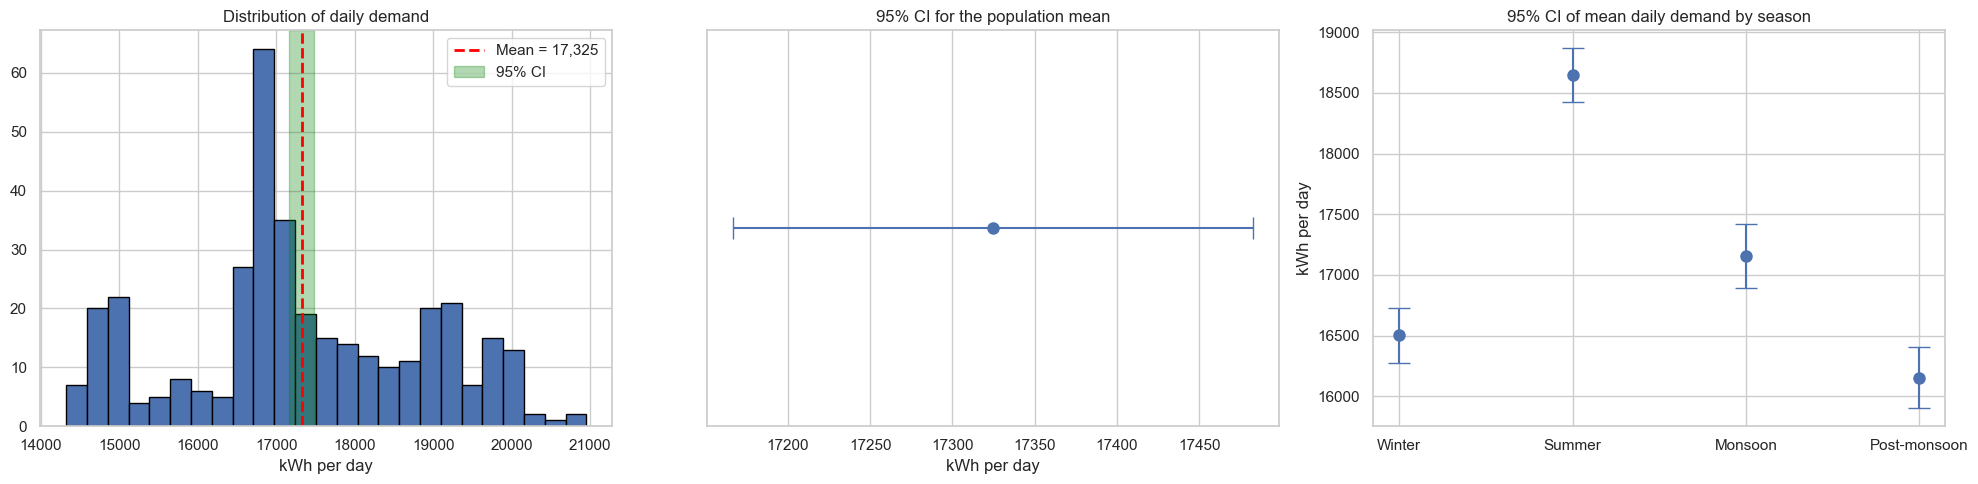

In [23]:
x = daily["Total_kWh"].dropna()
n = len(x); sample_mean = x.mean(); sample_std = x.std(ddof=1)
standard_error = sample_std / np.sqrt(n)
print(f"Sample size = {n}, mean = {sample_mean:,.2f}, std = {sample_std:,.2f}, SE = {standard_error:,.2f}")

for conf in (0.90, 0.95, 0.99):
    t_critical = stats.t.ppf((1 + conf) / 2, df=n - 1)
    margin = t_critical * standard_error
    print(f"{int(conf*100)}% CI: ({sample_mean - margin:,.1f}, {sample_mean + margin:,.1f})   margin = {margin:,.1f}")

margin_error = stats.t.ppf(0.975, n - 1) * standard_error
lower, upper = sample_mean - margin_error, sample_mean + margin_error

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].hist(x, bins=25, edgecolor="black")
axes[0].axvline(sample_mean, ls="--", lw=2, color="red", label=f"Mean = {sample_mean:,.0f}")
axes[0].axvspan(lower, upper, alpha=0.3, color="green", label="95% CI")
axes[0].set_title("Distribution of daily demand"); axes[0].set_xlabel("kWh per day"); axes[0].legend()

axes[1].errorbar(sample_mean, 1, xerr=margin_error, fmt="o", capsize=8, markersize=8)
axes[1].set_yticks([]); axes[1].set_xlabel("kWh per day")
axes[1].set_title("95% CI for the population mean")

ss = daily.groupby("Season")["Total_kWh"].agg(["mean", "std", "count"]).reindex(SEASON_ORDER)
ss["ci"] = stats.t.ppf(0.975, ss["count"] - 1) * ss["std"] / np.sqrt(ss["count"])
axes[2].errorbar(ss.index, ss["mean"], yerr=ss["ci"], fmt="o", capsize=8, markersize=8)
axes[2].set_title("95% CI of mean daily demand by season"); axes[2].set_ylabel("kWh per day")
plt.tight_layout(); plt.show()

### 9.2 One-sample Z-test
We test whether the true mean differs from it using a random sample of **60 days**.
For the Z-test the population standard deviation is treated as *known* (taken from the full-year history).

* H0: μ = mu0  vs  H1: μ ≠ mu0  (two-sided, α = 0.05)

---- One-sample Z-test ----
Hypothesised mean (mu0): 17,000 kWh | sample mean: 17,271.8 kWh | n = 60
Z-score: 1.3720 | P-value: 0.1701
Decision: Fail to reject H0 – no evidence of a difference


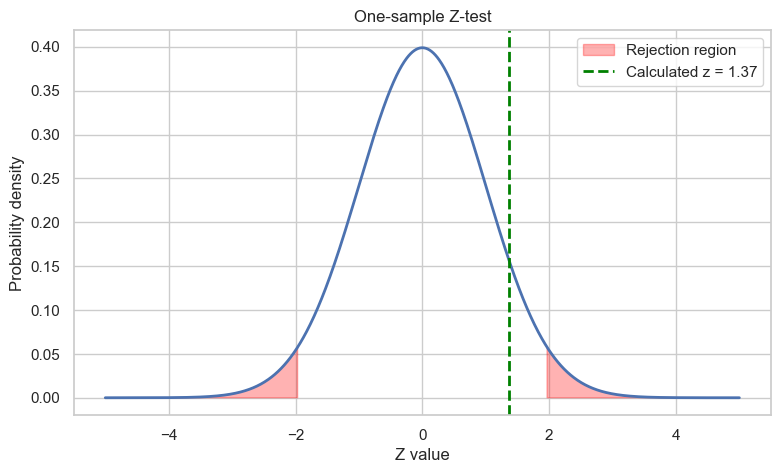

In [24]:
mu0 = round(daily["Total_kWh"].mean() * 0.98, -2)       # <- replace with your utility's planned figure if you have one
test_sample = daily["Total_kWh"].sample(n=60, random_state=42)
n_s = len(test_sample); xbar = test_sample.mean()
sigma_known = daily["Total_kWh"].std(ddof=0)
alpha = 0.05

z_score = (xbar - mu0) / (sigma_known / np.sqrt(n_s))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))

print("---- One-sample Z-test ----")
print(f"Hypothesised mean (mu0): {mu0:,.0f} kWh | sample mean: {xbar:,.1f} kWh | n = {n_s}")
print(f"Z-score: {z_score:.4f} | P-value: {p_value_z:.4f}")
print("Decision:", "Reject H0 – the mean differs from the benchmark" if p_value_z < alpha else "Fail to reject H0 – no evidence of a difference")

xs = np.linspace(-5, 5, 1000)
plt.figure(figsize=(9, 5))
plt.plot(xs, stats.norm.pdf(xs), lw=2)
z_crit = stats.norm.ppf(1 - alpha / 2)
plt.fill_between(xs, stats.norm.pdf(xs), where=(abs(xs) >= z_crit), alpha=0.3, color="red", label="Rejection region")
plt.axvline(z_score, color="green", lw=2, ls="--", label=f"Calculated z = {z_score:.2f}")
plt.xlabel("Z value"); plt.ylabel("Probability density"); plt.title("One-sample Z-test"); plt.legend(); plt.show()

### 9.3 One-sample t-test (population σ unknown) on the same sample

---- One-sample t-test ----
Hypothesised mean: 17,000 | t statistic: 1.4455 | P-value: 0.1536
Decision: Fail to reject H0


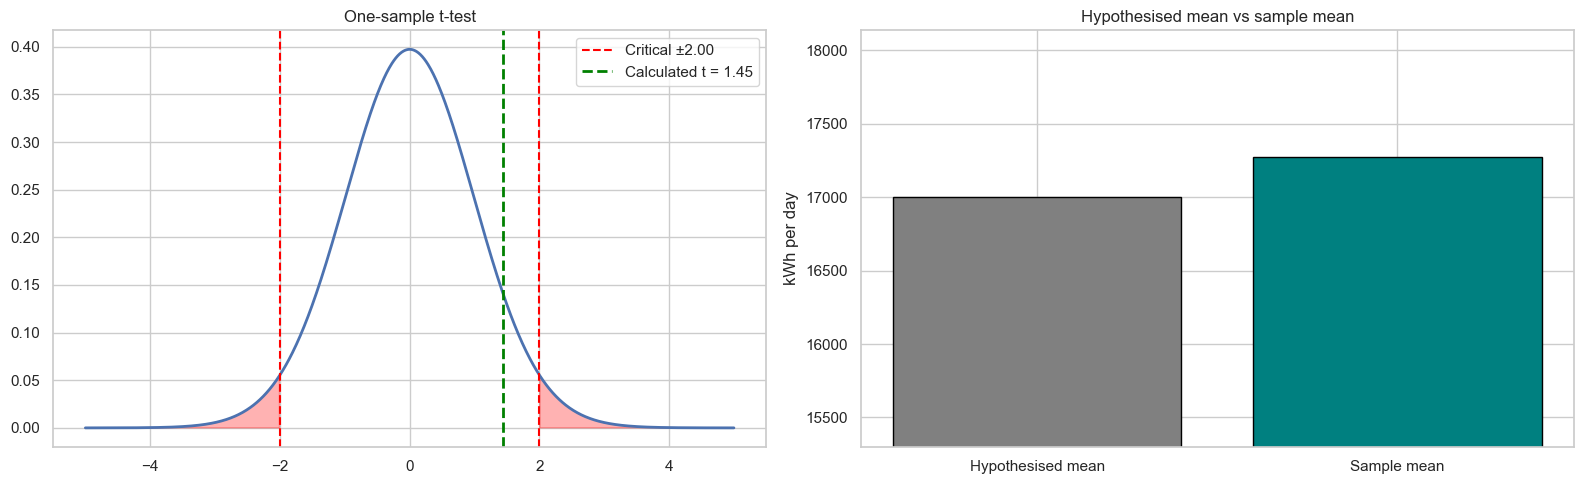

In [25]:
t_statistic, p_value_t = stats.ttest_1samp(test_sample, popmean=mu0)
print("---- One-sample t-test ----")
print(f"Hypothesised mean: {mu0:,.0f} | t statistic: {t_statistic:.4f} | P-value: {p_value_t:.4f}")
print("Decision:", "Reject H0" if p_value_t < alpha else "Fail to reject H0")

xs_t = np.linspace(-5, 5, 1000)
t_crit = stats.t.ppf(1 - alpha / 2, df=n_s - 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(xs_t, stats.t.pdf(xs_t, df=n_s - 1), lw=2)
axes[0].fill_between(xs_t, stats.t.pdf(xs_t, df=n_s - 1), where=(abs(xs_t) >= t_crit), alpha=0.3, color="red")
axes[0].axvline(-t_crit, ls="--", color="red", label=f"Critical ±{t_crit:.2f}")
axes[0].axvline(t_crit, ls="--", color="red")
axes[0].axvline(t_statistic, ls="--", color="green", lw=2, label=f"Calculated t = {t_statistic:.2f}")
axes[0].set_title("One-sample t-test"); axes[0].legend()

axes[1].bar(["Hypothesised mean", "Sample mean"], [mu0, xbar], edgecolor="black", color=["grey", "teal"])
axes[1].set_ylim(min(mu0, xbar) * 0.9, max(mu0, xbar) * 1.05)
axes[1].set_title("Hypothesised mean vs sample mean"); axes[1].set_ylabel("kWh per day")
plt.tight_layout(); plt.show()

## 10. Two-Sample t-test, CI of a Difference and ANOVA 

### 10.1 Weekday vs weekend demand
H0: mean demand on weekdays = mean demand on weekends  (α = 0.05)

Weekday: n=260, mean=17,934.8 | Weekend: n=105, mean=15,813.4
Levene test for equal variances: p = 0.0839 -> variances similar

Student t-test (equal variance): t = 15.2857, p = 4.499e-41
Welch t-test (unequal variance): t = 16.1885, p = 2.856e-39
Decision (Welch): Reject H0 – weekday and weekend demand differ

Difference in means (weekday - weekend) = 2,121.4 kWh
95% CI of the difference: (1,863.1, 2,379.6)


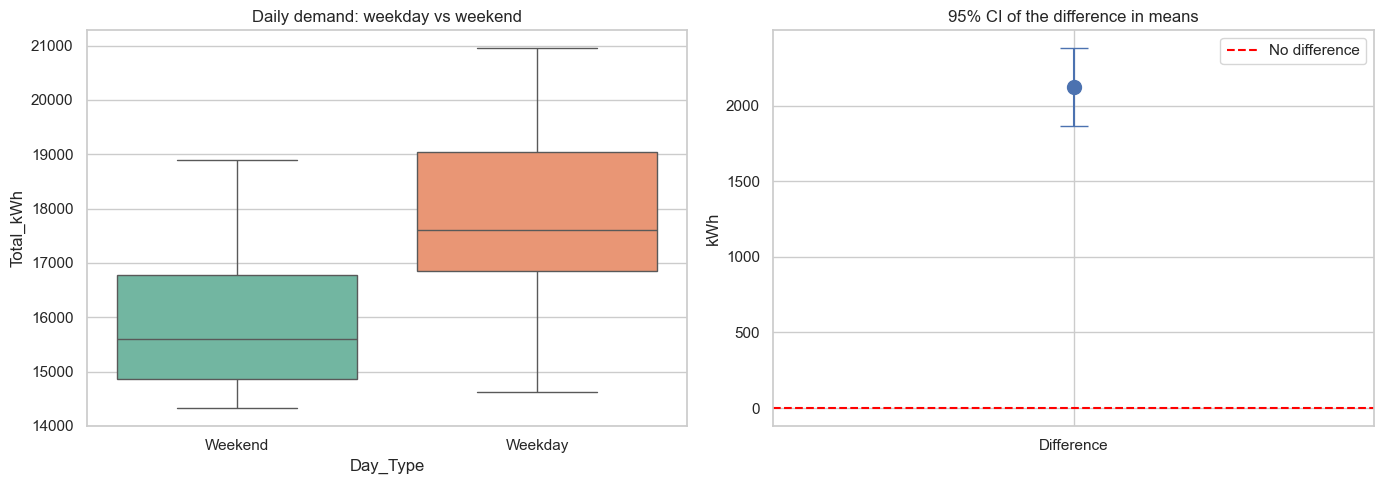

In [26]:
weekday = daily.loc[daily["Is_Weekend"] == 0, "Total_kWh"]
weekend = daily.loc[daily["Is_Weekend"] == 1, "Total_kWh"]
print(f"Weekday: n={len(weekday)}, mean={weekday.mean():,.1f} | Weekend: n={len(weekend)}, mean={weekend.mean():,.1f}")

lev_stat, lev_p = stats.levene(weekday, weekend)
print(f"Levene test for equal variances: p = {lev_p:.4f} ->", "variances similar" if lev_p > 0.05 else "variances differ (Welch is safer)")

t_eq, p_eq = stats.ttest_ind(weekday, weekend)                       # as in the practical
t_w, p_w = stats.ttest_ind(weekday, weekend, equal_var=False)         # Welch
print(f"\nStudent t-test (equal variance): t = {t_eq:.4f}, p = {p_eq:.4g}")
print(f"Welch t-test (unequal variance): t = {t_w:.4f}, p = {p_w:.4g}")
print("Decision (Welch):", "Reject H0 – weekday and weekend demand differ" if p_w < 0.05 else "Fail to reject H0")

# 95% confidence interval for the difference of means (Welch)
diff = weekday.mean() - weekend.mean()
v1, v2 = weekday.var(ddof=1) / len(weekday), weekend.var(ddof=1) / len(weekend)
se_diff = np.sqrt(v1 + v2)
dof = (v1 + v2) ** 2 / (v1 ** 2 / (len(weekday) - 1) + v2 ** 2 / (len(weekend) - 1))
ci_low, ci_high = stats.t.interval(0.95, dof, loc=diff, scale=se_diff)
print(f"\nDifference in means (weekday - weekend) = {diff:,.1f} kWh")
print(f"95% CI of the difference: ({ci_low:,.1f}, {ci_high:,.1f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=daily.assign(Day_Type=np.where(daily["Is_Weekend"] == 1, "Weekend", "Weekday")),
            x="Day_Type", y="Total_kWh", hue="Day_Type", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Daily demand: weekday vs weekend")
axes[1].errorbar(["Difference"], [diff], yerr=[[diff - ci_low], [ci_high - diff]], fmt="o", capsize=10, markersize=10)
axes[1].axhline(0, color="red", ls="--", label="No difference")
axes[1].set_title("95% CI of the difference in means"); axes[1].set_ylabel("kWh"); axes[1].legend()
plt.tight_layout(); plt.show()

### 10.2 One-way ANOVA – mean daily demand differ between the four seasons

In [27]:
groups = [daily.loc[daily["Season"] == s, "Total_kWh"] for s in SEASON_ORDER]
f_value, p_value = stats.f_oneway(*groups)
print("F-value:", round(f_value, 3))
print("P-value:", p_value)
print("Decision:", "Significant difference between seasons" if p_value < 0.05 else "No significant difference")

# Post-hoc: which pairs of seasons differ?
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=daily["Total_kWh"], groups=daily["Season"], alpha=0.05)
print("\nTukey HSD post-hoc test:")
print(tukey.summary())

F-value: 86.495
P-value: 3.434861441544542e-42
Decision: Significant difference between seasons

Tukey HSD post-hoc test:
          Multiple Comparison of Means - Tukey HSD, FWER=0.05           
   group1       group2     meandiff  p-adj    lower      upper    reject
------------------------------------------------------------------------
     Monsoon Post-monsoon  -999.5702    0.0 -1501.1534  -497.9871   True
     Monsoon       Summer  1489.4077    0.0  1069.9491  1908.8663   True
     Monsoon       Winter  -653.0451 0.0012 -1103.4225  -202.6678   True
Post-monsoon       Summer   2488.978    0.0  2012.6164  2965.3395   True
Post-monsoon       Winter   346.5251 0.2869  -157.2751   850.3253  False
      Summer       Winter -2142.4528    0.0 -2564.5601 -1720.3456   True
------------------------------------------------------------------------


### 10.3 Two-way ANOVA – Season × Consumer type 

,sum_sq,df,F,PR(>F)
C(Season),1.198162e+08,3.0,144.094373,1.452500e-78
C(Consumer_Type),1.741765e+10,2.0,31420.440546,0.000000e+00
C(Season):C(Consumer_Type),5.633908e+05,6.0,0.338775,9.164993e-01
Residual,3.001759e+08,1083.0,NaN,NaN


C(Season)                           p = 1.452e-78  -> significant
C(Consumer_Type)                    p = 0  -> significant
C(Season):C(Consumer_Type)          p = 0.9165  -> not significant


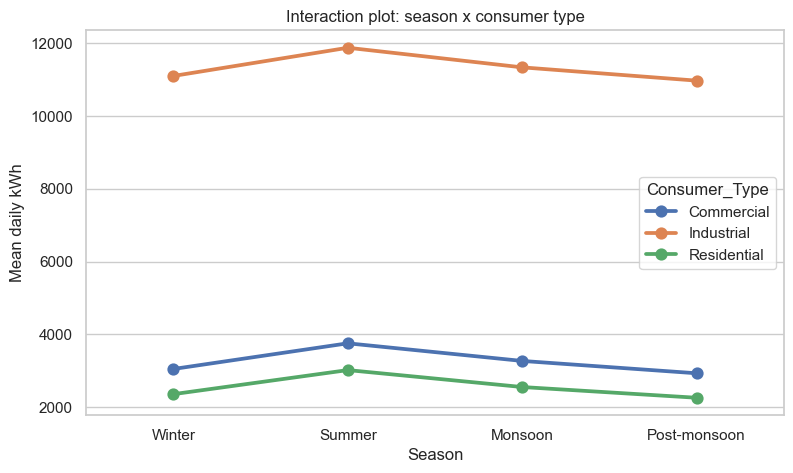

Non-parallel lines mean the effect of season depends on the consumer type (interaction).


In [28]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols("Daily_kWh ~ C(Season) + C(Consumer_Type) + C(Season):C(Consumer_Type)", data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
display(anova_table)

for term, p in anova_table["PR(>F)"].dropna().items():
    print(f"{term:35s} p = {p:.4g}  ->", "significant" if p < 0.05 else "not significant")

plt.figure(figsize=(9, 5))
sns.pointplot(data=df, x="Season", y="Daily_kWh", hue="Consumer_Type", order=SEASON_ORDER, markers="o", errorbar=None)
plt.title("Interaction plot: season x consumer type"); plt.ylabel("Mean daily kWh"); plt.show()
print("Non-parallel lines mean the effect of season depends on the consumer type (interaction).")

## 11. Covariance and Correlation  
daily demand related to temperature

* **Pearson** – strength of a *linear* relationship 
* **Spearman** – strength of a *monotonic* relationship

Covariance : 7228.03
Correlation: 0.7198
The variables have a positive relationship.

Pearson : r = 0.7198, p = 1.62e-59
Spearman: rho = 0.7264, p = 4.37e-61
Decision: Reject H0 – correlation is statistically significant


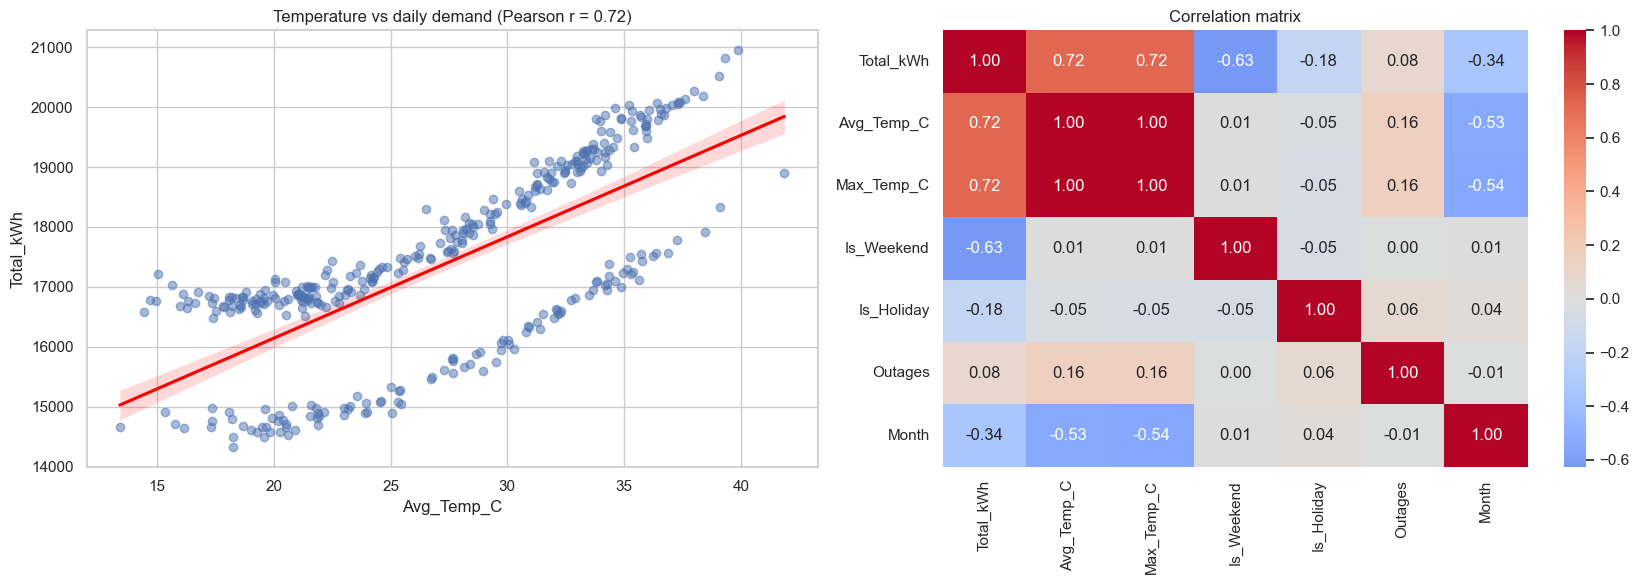

In [29]:
cov = daily["Avg_Temp_C"].cov(daily["Total_kWh"])
corr = daily["Avg_Temp_C"].corr(daily["Total_kWh"])
print("Covariance :", round(cov, 2))
print("Correlation:", round(corr, 4))
print("The variables have a", "positive" if corr > 0 else "negative" if corr < 0 else "no linear", "relationship.")

pearson_r, pearson_p = stats.pearsonr(daily["Avg_Temp_C"], daily["Total_kWh"])
spearman_r, spearman_p = stats.spearmanr(daily["Avg_Temp_C"], daily["Total_kWh"])
print(f"\nPearson : r = {pearson_r:.4f}, p = {pearson_p:.3g}")
print(f"Spearman: rho = {spearman_r:.4f}, p = {spearman_p:.3g}")
print("Decision:", "Reject H0 – correlation is statistically significant" if pearson_p < 0.05 else "Fail to reject H0")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.regplot(data=daily, x="Avg_Temp_C", y="Total_kWh", scatter_kws={"alpha": 0.5}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title(f"Temperature vs daily demand (Pearson r = {pearson_r:.2f})"); axes[0].grid(True)

cols = ["Total_kWh", "Avg_Temp_C", "Max_Temp_C", "Is_Weekend", "Is_Holiday", "Outages", "Month"]
sns.heatmap(daily[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 12. Regression – Predicting Daily Demand 

Target: `Total_kWh`.  Features: average temperature, maximum temperature, weekend flag, holiday flag, month.

### 12.1 Simple linear regression (temperature)

Intercept: 12,690.20 | Slope: 171.38
Regression equation: Total_kWh = 12,690.2 + 171.4 x Avg_Temp_C
Test R2 = 0.466


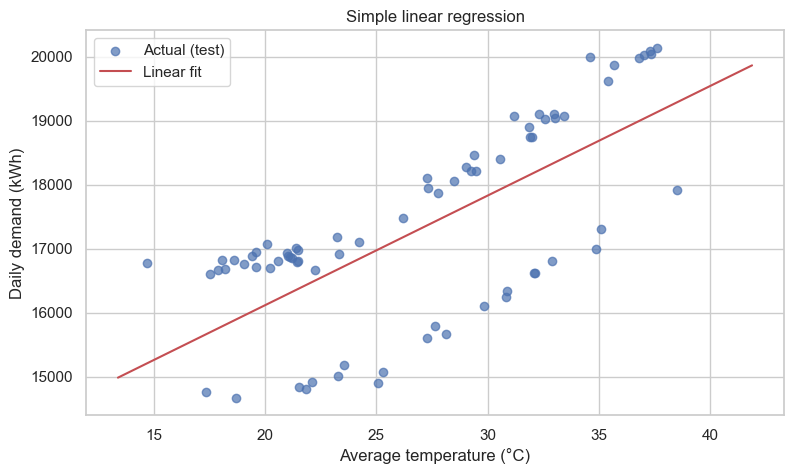

In [30]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve)

X1, y1 = daily[["Avg_Temp_C"]], daily["Total_kWh"]
X1_tr, X1_te, y1_tr, y1_te = train_test_split(X1, y1, test_size=0.2, random_state=42)
slr = LinearRegression().fit(X1_tr, y1_tr)
print(f"Intercept: {slr.intercept_:,.2f} | Slope: {slr.coef_[0]:,.2f}")
print(f"Regression equation: Total_kWh = {slr.intercept_:,.1f} + {slr.coef_[0]:,.1f} x Avg_Temp_C")
print(f"Test R2 = {r2_score(y1_te, slr.predict(X1_te)):.3f}")

plt.scatter(X1_te, y1_te, label="Actual (test)", alpha=0.7)
xs = np.linspace(X1["Avg_Temp_C"].min(), X1["Avg_Temp_C"].max(), 100).reshape(-1, 1)
plt.plot(xs, slr.predict(pd.DataFrame(xs, columns=["Avg_Temp_C"])), "r-", label="Linear fit")
plt.xlabel("Average temperature (°C)"); plt.ylabel("Daily demand (kWh)"); plt.title("Simple linear regression"); plt.legend(); plt.show()

### 12.2 Five regression models compared
All models are wrapped in a **pipeline with `StandardScaler`**

In [31]:
FEATURES = ["Avg_Temp_C", "Max_Temp_C", "Is_Weekend", "Is_Holiday", "Month"]
X, y = daily[FEATURES], daily["Total_kWh"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))

models = {
    "Linear Regression":        make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression":         make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso Regression":         make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
    "Decision Tree Regression": make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=5, random_state=42)),
    "Random Forest Regression": make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)),
}

predictions, results = {}, []
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    pred = mdl.predict(X_test)
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append([name, mse, mean_absolute_error(y_test, pred), np.sqrt(mse), r2_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=["Model", "MSE", "MAE", "RMSE", "R2"]).set_index("Model").sort_values("R2", ascending=False)
display(results_df.round(3))

comparison_df = pd.DataFrame({"Date": daily.loc[X_test.index, "Date"].dt.date.values, "Actual": y_test.values})
for name, pred in predictions.items():
    comparison_df[name] = pred.round(0)
display(comparison_df.head(10))

Training samples: 292 | Testing samples: 73


,MSE,MAE,RMSE,R2
Model,,,,
Random Forest Regression,29788.634,131.810,172.594,0.986
Decision Tree Regression,59606.229,174.079,244.144,0.973
Linear Regression,73953.411,219.701,271.944,0.966
Lasso Regression,74097.618,219.942,272.209,0.966
Ridge Regression,75780.406,221.692,275.282,0.965


,Date,Actual,Linear Regression,Ridge Regression,Lasso Regression,Decision Tree Regression,Random Forest Regression
0,2023-07-13,19992.00,19349.0,19378.0,19348.0,19598.0,19607.0
1,2023-02-03,16920.26,17163.0,17140.0,17164.0,17066.0,17007.0
2,2023-01-16,16885.73,16717.0,16721.0,16722.0,16791.0,16818.0
3,2023-11-06,17008.37,17159.0,17165.0,17157.0,16791.0,16826.0
4,2023-02-27,18748.07,18690.0,18680.0,18690.0,19048.0,18866.0
5,2023-07-03,19626.84,19495.0,19468.0,19489.0,19598.0,19742.0
6,2023-03-18,16341.47,16396.0,16405.0,16399.0,16344.0,16372.0
7,2023-04-30,17301.95,17185.0,17197.0,17186.0,17248.0,17249.0
8,2023-06-02,19107.09,18909.0,18885.0,18905.0,19048.0,18803.0
9,2023-05-07,17920.23,17820.0,17835.0,17820.0,18895.0,18077.0


Best model: Random Forest Regression | R2 = 0.9864


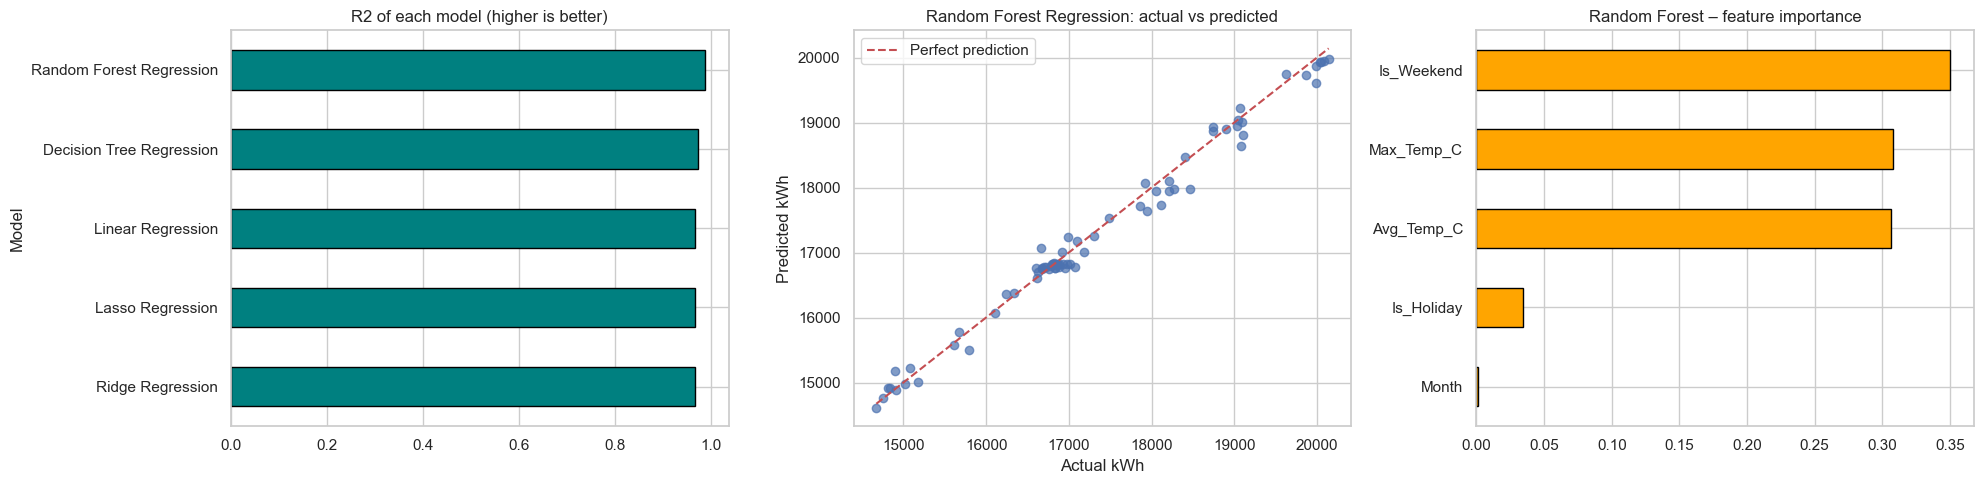

5-fold cross-validated R2 of Random Forest Regression: 0.935 (+/- 0.036)


In [32]:
best_name = results_df["R2"].idxmax()
best_model = models[best_name]
print("Best model:", best_name, "| R2 =", round(results_df.loc[best_name, "R2"], 4))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
results_df["R2"].plot(kind="barh", ax=axes[0], color="teal", edgecolor="black")
axes[0].set_title("R2 of each model (higher is better)"); axes[0].invert_yaxis()

axes[1].scatter(y_test, predictions[best_name], alpha=0.7)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", label="Perfect prediction")
axes[1].set_xlabel("Actual kWh"); axes[1].set_ylabel("Predicted kWh"); axes[1].set_title(f"{best_name}: actual vs predicted"); axes[1].legend()

rf = models["Random Forest Regression"][-1]
pd.Series(rf.feature_importances_, index=FEATURES).sort_values().plot(kind="barh", ax=axes[2], color="orange", edgecolor="black")
axes[2].set_title("Random Forest – feature importance")
plt.tight_layout(); plt.show()

cv = cross_val_score(best_model, X, y, cv=5, scoring="r2")
print(f"5-fold cross-validated R2 of {best_name}: {cv.mean():.3f} (+/- {cv.std():.3f})")

### 12.3 Build a prediction function with best model

In [33]:
joblib.dump(best_model, "best_demand_model.pkl")
loaded_model = joblib.load("best_demand_model.pkl")
print("Model saved as best_demand_model.pkl and loaded back")

def predict_demand(avg_temp, max_temp, is_weekend, is_holiday, month):
    row = pd.DataFrame([[avg_temp, max_temp, int(is_weekend), int(is_holiday), int(month)]], columns=FEATURES)
    pred = loaded_model.predict(row)[0]
    return f"Predicted total demand: {pred:,.0f} kWh  ({pred / 1000:,.1f} MWh)"

print(predict_demand(36, 43, False, False, 5), "<- hot May weekday")
print(predict_demand(20, 27, True,  False, 1), "<- cool January weekend")

Model saved as best_demand_model.pkl and loaded back
Predicted total demand: 19,812 kWh  (19.8 MWh) <- hot May weekday
Predicted total demand: 14,811 kWh  (14.8 MWh) <- cool January weekend


### 12.4 Interactive Gradio app

In [34]:
try:
    import gradio as gr
    interface = gr.Interface(
        fn=predict_demand,
        inputs=[gr.Number(label="Average temperature (°C)", value=30),
                gr.Number(label="Maximum temperature (°C)", value=36),
                gr.Checkbox(label="Weekend?"),
                gr.Checkbox(label="Public holiday?"),
                gr.Slider(1, 12, step=1, value=5, label="Month")],
        outputs="text",
        title="Electricity Demand Prediction System",
        description="Enter the weather and calendar details of a day to predict the total electricity demand.")
    interface.launch()
except ImportError:
    print("Gradio is not installed here - run  !pip install gradio  in Colab and re-run this cell.")

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## 13. Classification

### 13.1 Logistic Regression – will tomorrow be a *high-demand* day? 
`High_Demand = 1` if the day's demand is in the top 25 %, otherwise 0.

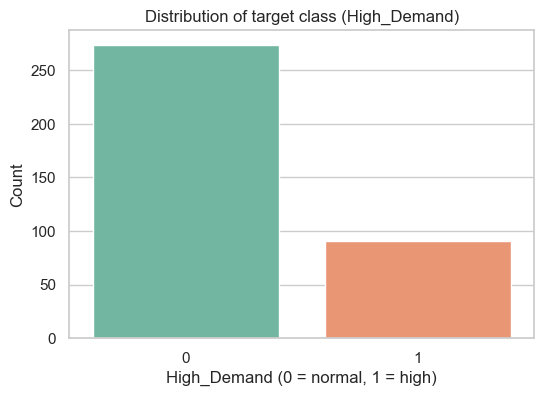

X_train: (292, 6) | X_test: (73, 6)

Accuracy: 0.9726 | ROC-AUC: 1.0000

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.96      0.98        55
           1       0.90      1.00      0.95        18

    accuracy                           0.97        73
   macro avg       0.95      0.98      0.96        73
weighted avg       0.98      0.97      0.97        73



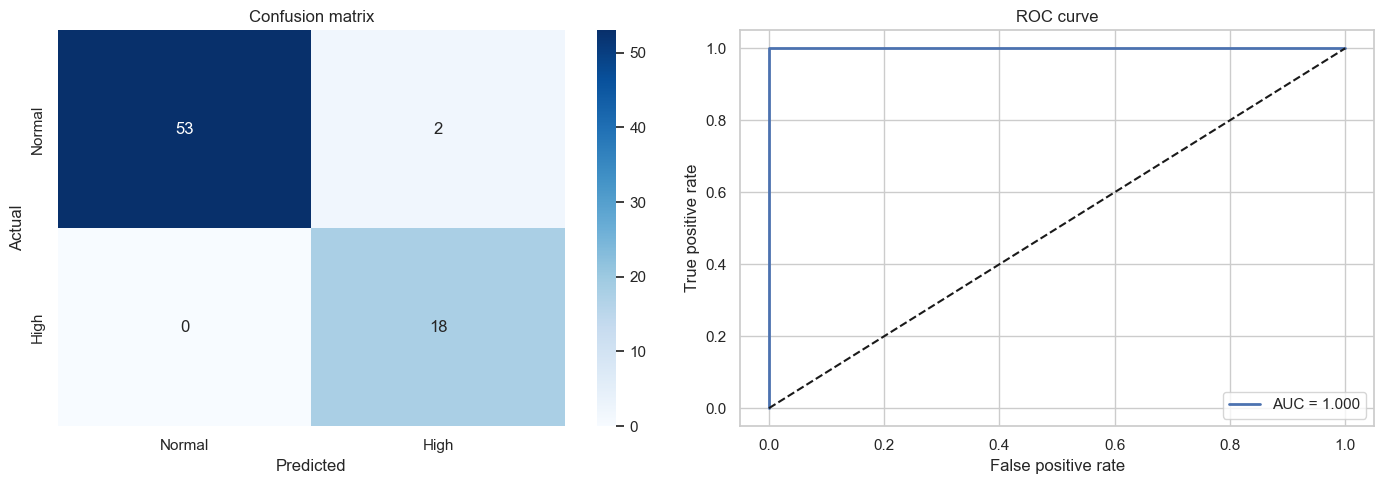

Standardised coefficients (positive = raises the chance of a high-demand day):
Is_Weekend   -2.902
Is_Holiday   -0.976
Month        -0.389
Outages       0.146
Max_Temp_C    2.478
Avg_Temp_C    2.592


In [35]:
daily["High_Demand"] = (daily["Total_kWh"] > daily["Total_kWh"].quantile(0.75)).astype(int)

plt.figure(figsize=(6, 4))
sns.countplot(x="High_Demand", data=daily, hue="High_Demand", palette="Set2", legend=False)
plt.title("Distribution of target class (High_Demand)")
plt.xlabel("High_Demand (0 = normal, 1 = high)"); plt.ylabel("Count"); plt.show()

CLF_FEATURES = ["Avg_Temp_C", "Max_Temp_C", "Is_Weekend", "Is_Holiday", "Month", "Outages"]
Xc, yc = daily[CLF_FEATURES], daily["High_Demand"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
print("X_train:", Xc_train.shape, "| X_test:", Xc_test.shape)

log_reg = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, random_state=42))
log_reg.fit(Xc_train, yc_train)
y_pred = log_reg.predict(Xc_test)
y_proba = log_reg.predict_proba(Xc_test)[:, 1]

log_acc = accuracy_score(yc_test, y_pred)
log_auc = roc_auc_score(yc_test, y_proba)
print(f"\nAccuracy: {log_acc:.4f} | ROC-AUC: {log_auc:.4f}")
print("\nClassification Report:\n", classification_report(yc_test, y_pred))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(confusion_matrix(yc_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Normal", "High"], yticklabels=["Normal", "High"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(yc_test, y_proba)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {log_auc:.3f}"); axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout(); plt.show()

coef = pd.Series(log_reg[-1].coef_[0], index=CLF_FEATURES).sort_values()
print("Standardised coefficients (positive = raises the chance of a high-demand day):")
print(coef.round(3).to_string())

### 13.2 K-Nearest Neighbours – classify day as Low / Medium / High demand  

Actual   : ['Low', 'Low', 'Medium', 'High', 'Medium', 'Low', 'Medium', 'High', 'Low', 'Medium', 'High', 'Medium', 'Medium', 'Low', 'Medium']
Predicted: ['Low', 'Medium', 'Low', 'High', 'Low', 'Low', 'Medium', 'High', 'Low', 'Low', 'High', 'Medium', 'Medium', 'Low', 'Medium']

Accuracy (k=3): 0.7808
Confusion matrix:
 [[19  5  0]
 [ 7 16  1]
 [ 0  3 22]]

Classification report:
               precision    recall  f1-score   support

         Low       0.73      0.79      0.76        24
      Medium       0.67      0.67      0.67        24
        High       0.96      0.88      0.92        25

    accuracy                           0.78        73
   macro avg       0.78      0.78      0.78        73
weighted avg       0.79      0.78      0.78        73



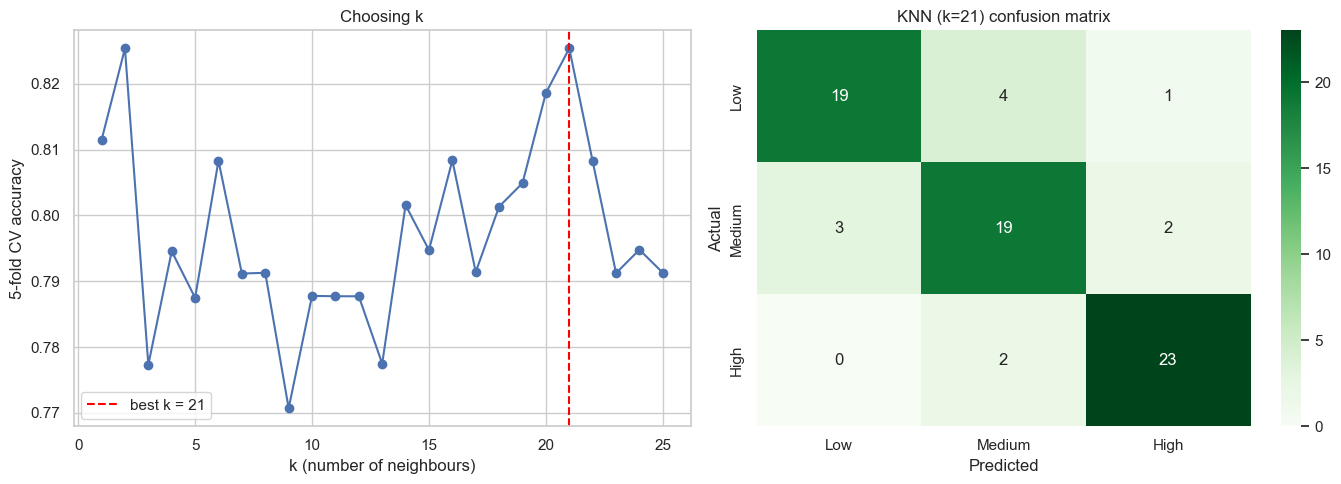

Test accuracy with tuned k = 21: 0.8356


In [36]:
daily["Demand_Level"] = pd.qcut(daily["Total_kWh"], 3, labels=["Low", "Medium", "High"]).astype(str)
LEVELS = ["Low", "Medium", "High"]
Xk, yk = daily[CLF_FEATURES], daily["Demand_Level"]
Xk_train, Xk_test, yk_train, yk_test = train_test_split(Xk, yk, test_size=0.2, random_state=42, stratify=yk)

def run_knn(k):
    mdl = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    mdl.fit(Xk_train, yk_train)
    return mdl, mdl.predict(Xk_test)

knn3, pred3 = run_knn(3)
print("Actual   :", list(yk_test.values[:15]))
print("Predicted:", list(pred3[:15]))
knn_acc3 = accuracy_score(yk_test, pred3)
print(f"\nAccuracy (k=3): {knn_acc3:.4f}")
print("Confusion matrix:\n", confusion_matrix(yk_test, pred3, labels=LEVELS))
print("\nClassification report:\n", classification_report(yk_test, pred3, labels=LEVELS))

# choose k by 5-fold cross-validation on the training data
k_range = range(1, 26)
cv_scores = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                             Xk_train, yk_train, cv=5).mean() for k in k_range]
best_k = list(k_range)[int(np.argmax(cv_scores))]
knn_best, pred_best = run_knn(best_k)
knn_acc_best = accuracy_score(yk_test, pred_best)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), cv_scores, marker="o"); axes[0].axvline(best_k, color="red", ls="--", label=f"best k = {best_k}")
axes[0].set_xlabel("k (number of neighbours)"); axes[0].set_ylabel("5-fold CV accuracy"); axes[0].set_title("Choosing k"); axes[0].legend()
sns.heatmap(confusion_matrix(yk_test, pred_best, labels=LEVELS), annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=LEVELS, yticklabels=LEVELS)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual"); axes[1].set_title(f"KNN (k={best_k}) confusion matrix")
plt.tight_layout(); plt.show()
print(f"Test accuracy with tuned k = {best_k}: {knn_acc_best:.4f}")

## 14. Summary

In [37]:
season_means = daily.groupby("Season")["Total_kWh"].mean().reindex(SEASON_ORDER)
print("=" * 70)
print("ELECTRICITY CONSUMPTION PATTERN ANALYSIS - KEY FINDINGS")
print("=" * 70)
print(f"1. Data: {len(hourly):,} hourly readings, {len(daily)} days, 3 consumer types.")
print(f"2. Daily pattern: system peak at {system_peak_hour}:00; per-type peak hours -> "
      + ", ".join(f"{k} {v}:00" for k, v in peak_table['Peak_Hour'].items()))
print(f"3. Seasonality: highest demand in {season_means.idxmax()} ({season_means.max():,.0f} kWh/day), "
      f"lowest in {season_means.idxmin()} ({season_means.min():,.0f} kWh/day).")
print(f"4. Weekday vs weekend: difference {diff:,.0f} kWh/day, 95% CI ({ci_low:,.0f}, {ci_high:,.0f}), Welch p = {p_w:.3g}.")
print(f"5. ANOVA: season effect p = {p_value:.3g}; two-way ANOVA tested season, consumer type and their interaction.")
print(f"6. Temperature vs demand: Pearson r = {pearson_r:.2f}, Spearman rho = {spearman_r:.2f}.")
print(f"7. Best regression model: {best_name} (R2 = {results_df.loc[best_name, 'R2']:.3f}, RMSE = {results_df.loc[best_name, 'RMSE']:,.0f} kWh).")
print(f"8. High-demand-day classifier (Logistic Regression): accuracy {log_acc:.3f}, AUC {log_auc:.3f}.")
print(f"9. Demand-level classifier (KNN): accuracy {knn_acc3:.3f} with k=3, {knn_acc_best:.3f} with tuned k={best_k}.")
print("=" * 70)
print("Files created: electricity_hourly.csv, electricity_daily.csv, countries_electricity.csv, best_demand_model.pkl")

ELECTRICITY CONSUMPTION PATTERN ANALYSIS - KEY FINDINGS
1. Data: 26,280 hourly readings, 365 days, 3 consumer types.
2. Daily pattern: system peak at 14:00; per-type peak hours -> Commercial 14:00, Industrial 14:00, Residential 20:00
3. Seasonality: highest demand in Summer (18,644 kWh/day), lowest in Post-monsoon (16,155 kWh/day).
4. Weekday vs weekend: difference 2,121 kWh/day, 95% CI (1,863, 2,380), Welch p = 2.86e-39.
5. ANOVA: season effect p = 3.43e-42; two-way ANOVA tested season, consumer type and their interaction.
6. Temperature vs demand: Pearson r = 0.72, Spearman rho = 0.73.
7. Best regression model: Random Forest Regression (R2 = 0.986, RMSE = 173 kWh).
8. High-demand-day classifier (Logistic Regression): accuracy 0.973, AUC 1.000.
9. Demand-level classifier (KNN): accuracy 0.781 with k=3, 0.836 with tuned k=21.
Files created: electricity_hourly.csv, electricity_daily.csv, countries_electricity.csv, best_demand_model.pkl


### Conclusion
Electricity demand follows clear, explainable patterns: daily peaks that differ by consumer type, a strong seasonal / temperature effect, and weekday-weekend differences that are statistically significant.
Because these patterns are stable, even simple models predict daily demand well, which supports **load planning, tariff design and peak-hour management**.

## 15. Streamlit Dashboard – web UI for the analysis and predictions

This section turns the notebook into a **web dashboard** with four pages: *Overview*, *Patterns*, *Statistical tests* and *Predictions* (live demand predictor + model comparison).
It reads the CSV files created in Section 3 (`electricity_hourly.csv`, `electricity_daily.csv`), so **run the notebook from the top first**.

Steps: **15.1** install + check files → **15.2** write `app.py` → **15.3** launch with a public link (Colab) → **15.4** optional permanent link (Streamlit Community Cloud).

### 15.1 Install Streamlit and check that the data files exist

In [38]:
!pip install -q streamlit
import os

# the dashboard reads these two files (created in Section 3)
for f in ["electricity_hourly.csv", "electricity_daily.csv"]:
    assert os.path.exists(f), f"{f} not found - run Section 3 first"
print("Data files found")

# needed only for the permanent deployment in 15.4
with open("requirements.txt", "w") as f:
    f.write("streamlit\npandas\nnumpy\nscipy\nscikit-learn\nmatplotlib\nseaborn\n")
print("requirements.txt written")

Data files found
requirements.txt written



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\ACER\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


### 15.2 Write the dashboard code to `app.py`

In [39]:
%%writefile app.py
import numpy as np
import pandas as pd
import scipy.stats as stats
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, roc_auc_score

st.set_page_config(page_title="Electricity Consumption Dashboard", page_icon="⚡", layout="wide")

SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
FEATURES = ["Avg_Temp_C", "Max_Temp_C", "Is_Weekend", "Is_Holiday", "Month"]
CLF_FEATURES = FEATURES + ["Outages"]


@st.cache_data
def load_data():
    hourly = pd.read_csv("electricity_hourly.csv", parse_dates=["Timestamp", "Date"])
    daily = pd.read_csv("electricity_daily.csv", parse_dates=["Date"])
    return hourly, daily


@st.cache_resource
def train_models(daily):
    X, y = daily[FEATURES], daily["Total_kWh"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    models = {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Lasso Regression": make_pipeline(StandardScaler(), Lasso(alpha=1.0)),
        "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeRegressor(max_depth=5, random_state=42)),
        "Random Forest": make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)),
    }
    rows, preds = [], {}
    for name, m in models.items():
        m.fit(Xtr, ytr)
        p = m.predict(Xte)
        preds[name] = p
        rows.append({"Model": name, "R2": r2_score(yte, p), "RMSE": np.sqrt(mean_squared_error(yte, p)),
                     "MAE": mean_absolute_error(yte, p)})
    res = pd.DataFrame(rows).set_index("Model").sort_values("R2", ascending=False)
    best = res.index[0]
    cv = cross_val_score(models[best], X, y, cv=5, scoring="r2")

    d = daily.copy()
    d["High_Demand"] = (d["Total_kWh"] > d["Total_kWh"].quantile(0.75)).astype(int)
    a, b, c, e = train_test_split(d[CLF_FEATURES], d["High_Demand"], test_size=0.2, random_state=42, stratify=d["High_Demand"])
    logreg = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, random_state=42)).fit(a, c)
    log_acc = accuracy_score(e, logreg.predict(b))
    log_auc = roc_auc_score(e, logreg.predict_proba(b)[:, 1])

    d["Level"] = pd.qcut(d["Total_kWh"], 3, labels=["Low", "Medium", "High"]).astype(str)
    a, b, c, e = train_test_split(d[CLF_FEATURES], d["Level"], test_size=0.2, random_state=42, stratify=d["Level"])
    cvs = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), a, c, cv=5).mean() for k in range(1, 26)]
    best_k = int(np.argmax(cvs)) + 1
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(a, c)
    knn_acc = accuracy_score(e, knn.predict(b))
    return dict(res=res, best=best, model=models[best], cv=cv, yte=yte, pred=preds[best], logreg=logreg,
                log_acc=log_acc, log_auc=log_auc, knn_acc=knn_acc, best_k=best_k, knn_cv=cvs, models=models)


hourly, daily = load_data()
M = train_models(daily)

st.sidebar.title("⚡ Electricity Dashboard")
page = st.sidebar.radio("Go to", ["Overview", "Patterns", "Statistical tests", "Predictions"])
st.sidebar.caption("Electricity Consumption Pattern Analysis · hourly smart-meter data, 2023")

st.title("⚡ Electricity Consumption Pattern Analysis")

# ------------------------------------------------------------------ Overview
if page == "Overview":
    prof = hourly.groupby(["Hour", "Consumer_Type"])["Consumption_kWh"].mean().unstack()
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("Average daily demand", f"{daily['Total_kWh'].mean():,.0f} kWh")
    c2.metric("System peak hour", f"{int(prof.sum(axis=1).idxmax())}:00")
    c3.metric("Highest day", f"{daily['Total_kWh'].max():,.0f} kWh")
    c4.metric("Hourly readings", f"{len(hourly):,}")

    left, right = st.columns(2)
    with left:
        st.subheader("Average hourly load profile")
        st.line_chart(prof)
    with right:
        st.subheader("Share of annual consumption")
        share = hourly.groupby("Consumer_Type")["Consumption_kWh"].sum()
        fig, ax = plt.subplots(figsize=(5, 4))
        ax.pie(share.values, labels=share.index, autopct="%1.1f%%", startangle=90)
        st.pyplot(fig)

    st.subheader("Daily demand through the year")
    yr = daily.set_index("Date")[["Total_kWh"]].rename(columns={"Total_kWh": "Daily"})
    yr["7-day average"] = yr["Daily"].rolling(7).mean()
    st.line_chart(yr)

    st.subheader("Peak-hour table")
    pk = pd.DataFrame({"Peak hour": prof.idxmax(), "Peak load (kWh)": prof.max().round(1), "Average load (kWh)": prof.mean().round(1)})
    pk["Load factor"] = (pk["Average load (kWh)"] / pk["Peak load (kWh)"]).round(2)
    st.dataframe(pk)

# ------------------------------------------------------------------ Patterns
elif page == "Patterns":
    st.subheader("Weekly pattern: day of week × hour")
    th = hourly.groupby("Timestamp")["Consumption_kWh"].sum().reset_index()
    th["Hour"] = th["Timestamp"].dt.hour
    th["Day"] = th["Timestamp"].dt.day_name()
    heat = th.pivot_table(index="Day", columns="Hour", values="Consumption_kWh", aggfunc="mean").reindex(DAYS)
    fig, ax = plt.subplots(figsize=(13, 4))
    sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Average total load (kWh)"}, ax=ax)
    st.pyplot(fig)

    a, b = st.columns(2)
    with a:
        st.subheader("Average daily demand by month")
        mo = daily.groupby("Month")["Total_kWh"].mean()
        mo.index = [MONTHS[i - 1] for i in mo.index]
        st.bar_chart(mo)
    with b:
        st.subheader("Demand by season")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.boxplot(data=daily, x="Season", y="Total_kWh", order=SEASONS, hue="Season", palette="Set2", legend=False, ax=ax)
        st.pyplot(fig)

    c, d = st.columns(2)
    with c:
        st.subheader("Temperature vs daily demand")
        st.scatter_chart(daily, x="Avg_Temp_C", y="Total_kWh", color="Season")
    with d:
        st.subheader("Average demand by weekday")
        wk = daily.groupby(daily["Date"].dt.day_name())["Total_kWh"].mean().reindex(DAYS)
        st.bar_chart(wk)

    st.subheader("Unusual days (IQR rule)")
    q1, q3 = daily["Total_kWh"].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = daily[(daily["Total_kWh"] < q1 - 1.5 * iqr) | (daily["Total_kWh"] > q3 + 1.5 * iqr)]
    st.write(f"Fences: {q1 - 1.5 * iqr:,.0f} to {q3 + 1.5 * iqr:,.0f} kWh → **{len(out)}** unusual day(s).")
    if len(out):
        st.dataframe(out[["Date", "Total_kWh", "Avg_Temp_C"]])

# ------------------------------------------------------------------ Statistical tests
elif page == "Statistical tests":
    wd = daily.loc[daily["Is_Weekend"] == 0, "Total_kWh"]
    we = daily.loc[daily["Is_Weekend"] == 1, "Total_kWh"]
    t, p = stats.ttest_ind(wd, we, equal_var=False)
    diff = wd.mean() - we.mean()
    v1, v2 = wd.var() / len(wd), we.var() / len(we)
    dof = (v1 + v2) ** 2 / (v1 ** 2 / (len(wd) - 1) + v2 ** 2 / (len(we) - 1))
    lo, hi = stats.t.interval(0.95, dof, loc=diff, scale=np.sqrt(v1 + v2))
    st.subheader("Weekday vs weekend (Welch t-test)")
    a, b, c = st.columns(3)
    a.metric("Weekday mean", f"{wd.mean():,.0f} kWh")
    b.metric("Weekend mean", f"{we.mean():,.0f} kWh")
    c.metric("Difference", f"{diff:,.0f} kWh", f"95% CI {lo:,.0f} to {hi:,.0f}")
    st.write(f"t = {t:.2f}, p = {p:.3g} → " + ("**significant difference**" if p < 0.05 else "no significant difference"))

    st.subheader("Seasons (one-way ANOVA)")
    F, pa = stats.f_oneway(*[daily.loc[daily["Season"] == s, "Total_kWh"] for s in SEASONS])
    st.write(f"F = {F:.1f}, p = {pa:.3g} → " + ("**demand differs between seasons**" if pa < 0.05 else "no significant difference"))
    st.dataframe(daily.groupby("Season")["Total_kWh"].agg(["mean", "std", "min", "max"]).reindex(SEASONS).round(0))

    st.subheader("Temperature vs demand (correlation)")
    pr, pp = stats.pearsonr(daily["Avg_Temp_C"], daily["Total_kWh"])
    sr, _ = stats.spearmanr(daily["Avg_Temp_C"], daily["Total_kWh"])
    st.write(f"Pearson r = {pr:.3f} (p = {pp:.3g}), Spearman ρ = {sr:.3f}")
    cols = ["Total_kWh", "Avg_Temp_C", "Max_Temp_C", "Is_Weekend", "Is_Holiday", "Outages", "Month"]
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(daily[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    st.pyplot(fig)

# ------------------------------------------------------------------ Predictions
else:
    left, right = st.columns([1, 1])
    with left:
        st.subheader("Predict a day's demand")
        avg_t = st.slider("Average temperature (°C)", 10.0, 42.0, 30.0, 0.5)
        max_t = st.slider("Maximum temperature (°C)", 15.0, 48.0, 36.0, 0.5)
        month = st.select_slider("Month", options=list(range(1, 13)), value=5, format_func=lambda m: MONTHS[m - 1])
        outages = st.slider("Expected power cuts", 0, 5, 0)
        weekend = st.checkbox("Weekend")
        holiday = st.checkbox("Public holiday")
        max_t = max(max_t, avg_t)
        row = pd.DataFrame([[avg_t, max_t, int(weekend), int(holiday), month]], columns=FEATURES)
        kwh = float(M["model"].predict(row)[0])
        prob = float(M["logreg"].predict_proba(pd.DataFrame([[avg_t, max_t, int(weekend), int(holiday), month, outages]], columns=CLF_FEATURES))[0, 1])
        st.metric(f"Predicted total demand ({M['best']})", f"{kwh:,.0f} kWh", f"{kwh / 1000:,.1f} MWh", delta_color="off")
        st.metric("Chance of a high-demand day", f"{prob * 100:.0f}%")
        st.progress(min(max(prob, 0.0), 1.0))
        st.write("🔴 **High-demand day likely**" if prob > 0.5 else "🟢 Normal day expected")
    with right:
        st.subheader("Model comparison (test set)")
        st.dataframe(M["res"].round(3))
        st.caption(f"Best model: {M['best']} · 5-fold CV R² = {M['cv'].mean():.3f} (± {M['cv'].std():.3f})")
        st.write(f"Logistic Regression accuracy **{M['log_acc']:.3f}**, AUC **{M['log_auc']:.3f}** · "
                 f"KNN (k={M['best_k']}) accuracy **{M['knn_acc']:.3f}**")

    a, b = st.columns(2)
    with a:
        st.subheader("Actual vs predicted")
        ap = pd.DataFrame({"Actual": M["yte"].values, "Predicted": M["pred"]})
        st.scatter_chart(ap, x="Actual", y="Predicted")
    with b:
        st.subheader("Typical-weekday forecast by month")
        clim = daily.groupby("Month")[["Avg_Temp_C", "Max_Temp_C"]].mean()
        fc = pd.DataFrame({"Avg_Temp_C": clim["Avg_Temp_C"], "Max_Temp_C": clim["Max_Temp_C"],
                           "Is_Weekend": 0, "Is_Holiday": 0, "Month": clim.index})[FEATURES]
        out = pd.DataFrame({"Predicted typical weekday": M["model"].predict(fc),
                            "Observed monthly average": daily.groupby("Month")["Total_kWh"].mean().values},
                           index=[MONTHS[m - 1] for m in clim.index])
        st.line_chart(out)


Overwriting app.py


### 15.3 Launch the dashboard and get a public link (Google Colab)
Streamlit runs on port 8501 inside Colab, and **localtunnel** exposes it as a public `https://….loca.lt` URL.

1. Run the cell below and wait a few seconds.
2. Copy the printed **IP address** - this is the "tunnel password" that localtunnel asks for on the first visit.
3. Open the `your url is: https://….loca.lt` link and paste the password.

The cell keeps running while the dashboard is online. Stop the cell to shut it down. The link works only while the Colab session is active - see 15.4 for a permanent one.

In [40]:
import subprocess, time, urllib.request

# start Streamlit in the background
server = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(6)

# localtunnel password = this Colab machine's public IP
ip = urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip()
print("Tunnel password (paste it on the localtunnel page):", ip)

# prints "your url is: https://....loca.lt"  (keep this cell running)
!npx -y localtunnel --port 8501

Tunnel password (paste it on the localtunnel page): 47.11.21.99


'npx' is not recognized as an internal or external command,
operable program or batch file.


### 15.4 (Optional) Permanent public link with Streamlit Community Cloud
1. In Colab's **Files** panel (left), download `app.py`, `requirements.txt`, `electricity_hourly.csv` and `electricity_daily.csv`.
2. Create a new **public GitHub repository** and upload those four files to its root.
3. Go to **share.streamlit.io** → *Create app* → pick the repository, branch `main`, main file `app.py` → **Deploy**.

You get a permanent link such as `https://<your-app-name>.streamlit.app` that works without Colab running.